<a href="https://colab.research.google.com/github/vinaykumarbakka104/CSA47-DEEP-LEARNING/blob/main/Copy_of_Untitled0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Customer-Genre Matrix:
 [[5 4 1 2 3]
 [4 5 1 2 2]
 [1 2 5 4 3]
 [2 1 4 5 3]
 [5 3 2 1 4]
 [1 3 4 5 2]]

Genre-Book Matrix:
 [[0.9 0.2 0.1 0.3]
 [0.8 0.3 0.2 0.1]
 [0.1 0.9 0.7 0.2]
 [0.2 0.8 0.9 0.3]
 [0.3 0.2 0.4 0.9]]

Dot Product of Customer 1 and 2: 51

Customer-Book Score Matrix:
 [[9.1 5.3 5.  5.4]
 [8.7 5.2 4.7 4.3]
 [4.7 9.1 8.8 5.4]
 [4.9 8.9 8.9 5.7]
 [8.5 5.3 5.  6.1]
 [5.3 9.1 8.8 4.7]]

Transpose of Customer Matrix:
 [[5 4 1 2 5 1]
 [4 5 2 1 3 3]
 [1 1 5 4 2 4]
 [2 2 4 5 1 5]
 [3 2 3 3 4 2]]

Inverse of Matrix A:
 [[ 0.6 -0.2]
 [-0.2  0.4]]

Element-wise Addition:
 [[10  8  2  4  6]
 [ 8 10  2  4  4]
 [ 2  4 10  8  6]
 [ 4  2  8 10  6]
 [10  6  4  2  8]
 [ 2  6  8 10  4]]

Element-wise Multiplication:
 [[25 16  1  4  9]
 [16 25  1  4  4]
 [ 1  4 25 16  9]
 [ 4  1 16 25  9]
 [25  9  4  1 16]
 [ 1  9 16 25  4]]

Element-wise Square:
 [[25 16  1  4  9]
 [16 25  1  4  4]
 [ 1  4 25 16  9]
 [ 4  1 16 25  9]
 [25  9  4  1 16]
 [ 1  9 16 25  4]]

Cosine Similarity Matrix:
 [[1.  

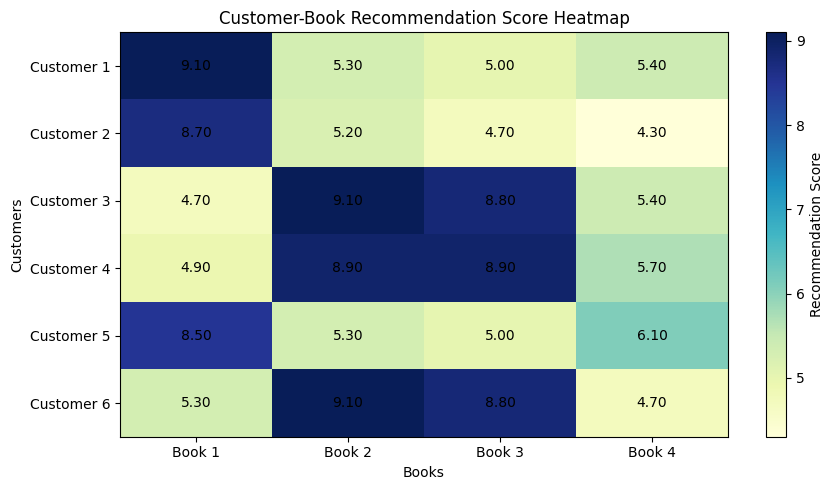

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------
# 1. Create Customer and Book Matrices
# ----------------------------------

# 6 customers and 5 genres
C = np.array([
    [5, 4, 1, 2, 3],
    [4, 5, 1, 2, 2],
    [1, 2, 5, 4, 3],
    [2, 1, 4, 5, 3],
    [5, 3, 2, 1, 4],
    [1, 3, 4, 5, 2]
])

# 5 genres and 4 books
B = np.array([
    [0.9, 0.2, 0.1, 0.3],
    [0.8, 0.3, 0.2, 0.1],
    [0.1, 0.9, 0.7, 0.2],
    [0.2, 0.8, 0.9, 0.3],
    [0.3, 0.2, 0.4, 0.9]
])

print("Customer-Genre Matrix:\n", C)
print("\nGenre-Book Matrix:\n", B)

# ----------------------------------
# 2. Vector and Matrix Operations
# ----------------------------------

# Dot product of two customer vectors
dot_product = np.dot(C[0], C[1])
print("\nDot Product of Customer 1 and 2:", dot_product)

# Matrix multiplication
S = np.dot(C, B)
print("\nCustomer-Book Score Matrix:\n", S)

# Transpose
print("\nTranspose of Customer Matrix:\n", C.T)

# Inverse (using a square matrix)
A = np.array([
    [2, 1],
    [1, 3]
])

print("\nInverse of Matrix A:\n", np.linalg.inv(A))

# Element-wise operations
print("\nElement-wise Addition:\n", C + C)
print("\nElement-wise Multiplication:\n", C * C)
print("\nElement-wise Square:\n", np.square(C))

# ----------------------------------
# 3. Cosine Similarity
# ----------------------------------

norms = np.linalg.norm(C, axis=1)

cosine_similarity = (
    C @ C.T
) / np.outer(norms, norms)

print("\nCosine Similarity Matrix:\n",
      np.round(cosine_similarity, 3))

# Find the two most similar distinct customers
similarity_copy = cosine_similarity.copy()
np.fill_diagonal(similarity_copy, -1)

i, j = np.unravel_index(
    np.argmax(similarity_copy),
    similarity_copy.shape
)

print("\nMost Similar Customers:")
print("Customer", i + 1, "and Customer", j + 1)
print("Similarity Score:",
      round(cosine_similarity[i, j], 4))

# ----------------------------------
# 4. Dense Layer: y = Wx + b
# ----------------------------------

# First customer
x = C[0]

# Weight matrix and bias vector
W = B.T
b = np.array([0.5, 0.5, 0.5, 0.5])

# Manual dense layer calculation
y = W @ x + b

print("\nDense Layer Calculation")
print("Input x:", x)
print("Weight Matrix W:\n", W)
print("Bias b:", b)
print("Output y = Wx + b:", y)

# Verify using matrix multiplication
print("Verification:", np.allclose(y, S[0] + b))

# ----------------------------------
# 5. Heatmap Visualization
# ----------------------------------

plt.figure(figsize=(9, 5))

plt.imshow(S, cmap='YlGnBu', aspect='auto')

plt.colorbar(label='Recommendation Score')

plt.xticks(
    range(4),
    ['Book 1', 'Book 2', 'Book 3', 'Book 4']
)

plt.yticks(
    range(6),
    ['Customer 1', 'Customer 2',
     'Customer 3', 'Customer 4',
     'Customer 5', 'Customer 6']
)

plt.title('Customer-Book Recommendation Score Heatmap')
plt.xlabel('Books')
plt.ylabel('Customers')

# Display score values
for i in range(6):
    for j in range(4):
        plt.text(
            j, i, f'{S[i, j]:.2f}',
            ha='center', va='center',
            color='black'
        )

plt.tight_layout()
plt.show()


Original Dataset:
   Haemoglobin        RBC     Glucose  Cholesterol        BMI
0    14.245071   9.288194   70.139309   247.213421  28.753135
1    13.292604   9.124252   95.015624   189.858026  22.935821
2    14.471533   9.791291  110.131092   246.549557  25.384483
3    15.784545  10.167645  111.174515   258.450214  23.150899
4    13.148770   7.918029   98.748363   230.317465  23.262015

Standardised Dataset:
   Haemoglobin       RBC   Glucose  Cholesterol       BMI
0     0.577318  0.534852 -1.517816     0.830650  0.847373
1    -0.104719  0.318357 -0.516799    -0.978860 -0.673997
2     0.739481  1.199220  0.091444     0.809705 -0.033612
3     1.679693  1.696217  0.133431     1.185160 -0.617749
4    -0.207714 -1.274529 -0.366595     0.297598 -0.588689

Covariance Matrix:
             Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.627658 -0.134197     0.058591 -0.031206
RBC             0.627658  1.000000 -0.099759    -0.060184 -0.128343
Glucose        

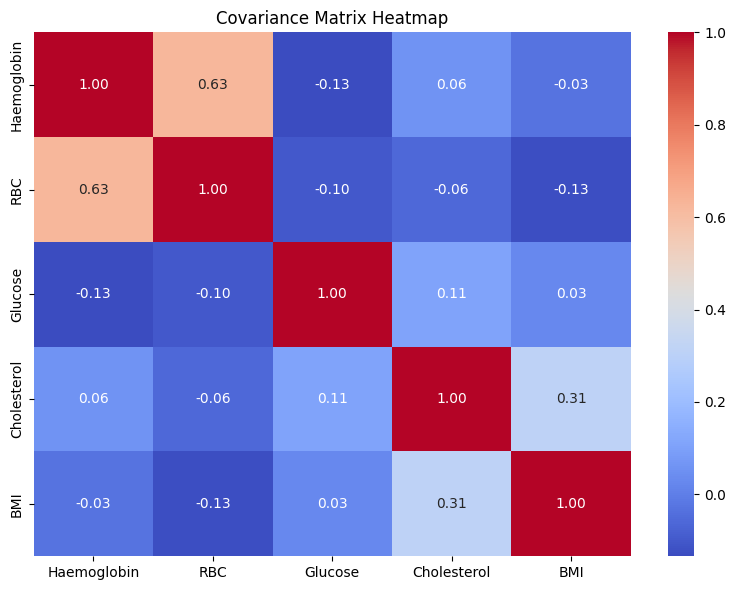


Correlation Matrix:
             Haemoglobin       RBC   Glucose  Cholesterol       BMI
Haemoglobin     1.000000  0.627658 -0.134197     0.058591 -0.031206
RBC             0.627658  1.000000 -0.099759    -0.060184 -0.128343
Glucose        -0.134197 -0.099759  1.000000     0.105993  0.025853
Cholesterol     0.058591 -0.060184  0.105993     1.000000  0.309934
BMI            -0.031206 -0.128343  0.025853     0.309934  1.000000


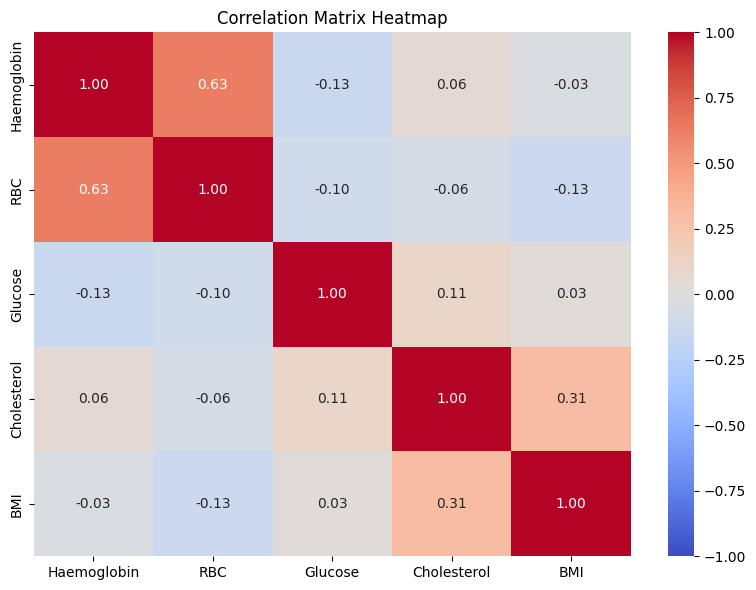


Eigenvalues:
[1.69914918 1.30969928 0.96543111 0.66814561 0.35757481]

Eigenvectors:
[[-0.64759055 -0.28132614  0.07988761  0.04283115 -0.70232866]
 [-0.67001273 -0.13201991  0.17631952  0.12272129  0.69821529]
 [ 0.24941192 -0.12797648  0.93212704  0.22147891 -0.05917753]
 [ 0.14019273 -0.70092828  0.03718577 -0.6890086   0.11370974]
 [ 0.22326913 -0.62908498 -0.30378576  0.67773093  0.05289596]]

Percentage of Variance:
PC1: 33.98%
PC2: 26.19%
PC3: 19.31%
PC4: 13.36%
PC5: 7.15%

Cumulative Variance: [ 33.98298367  60.17696934  79.48559154  92.84850383 100.        ]


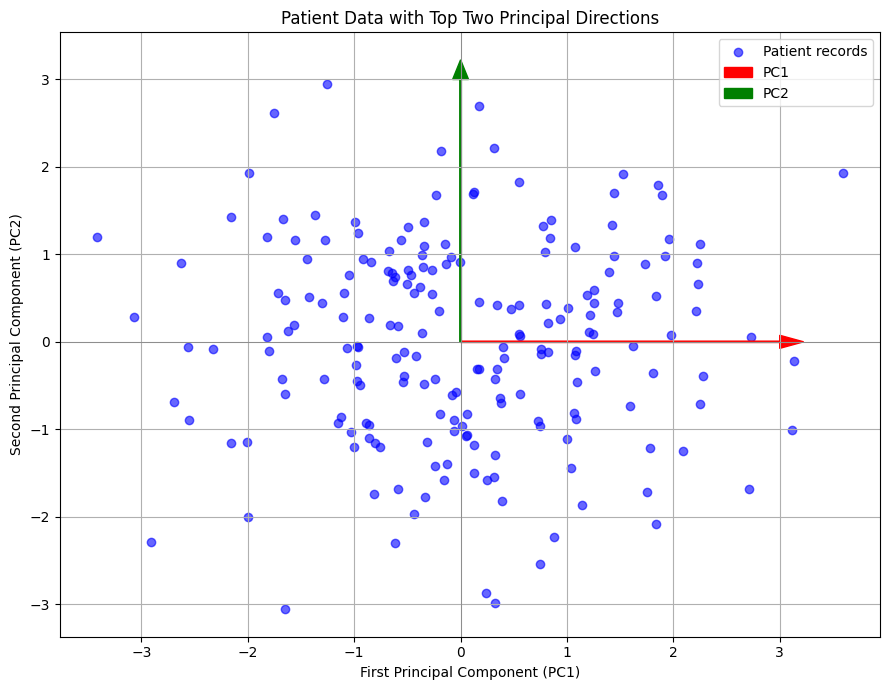

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------
# 1. Generate sample patient data
# --------------------------------

np.random.seed(42)
n = 200

data = pd.DataFrame({
    'Haemoglobin': np.random.normal(13.5, 1.5, n),
    'RBC': np.random.normal(4.8, 0.6, n),
    'Glucose': np.random.normal(110, 25, n),
    'Cholesterol': np.random.normal(190, 30, n),
    'BMI': np.random.normal(25, 4, n)
})

# Introduce some correlations
data['RBC'] = 0.3 * data['Haemoglobin'] + data['RBC']
data['Cholesterol'] = (
    data['Cholesterol'] + 1.2 * data['BMI']
)

print("Original Dataset:")
print(data.head())

# --------------------------------
# 2. Standardise the features
# --------------------------------

standardized_data = (
    data - data.mean()
) / data.std(ddof=1)

print("\nStandardised Dataset:")
print(standardized_data.head())

# --------------------------------
# 3. Covariance Matrix
# --------------------------------

cov_matrix = standardized_data.cov()

print("\nCovariance Matrix:")
print(cov_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cov_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Covariance Matrix Heatmap")
plt.tight_layout()
plt.show()

# --------------------------------
# 4. Correlation Matrix
# --------------------------------

corr_matrix = standardized_data.corr()

print("\nCorrelation Matrix:")
print(corr_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix Heatmap")
plt.tight_layout()
plt.show()

# --------------------------------
# 5. Eigenvalues and Eigenvectors
# --------------------------------

eigenvalues, eigenvectors = np.linalg.eigh(
    cov_matrix
)

# Sort in descending order
idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("\nEigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

# --------------------------------
# 6. Percentage of variance
# --------------------------------

total_variance = np.sum(eigenvalues)

variance_percentage = (
    eigenvalues / total_variance
) * 100

print("\nPercentage of Variance:")
for i, percentage in enumerate(variance_percentage):
    print(f"PC{i+1}: {percentage:.2f}%")

print(
    "\nCumulative Variance:",
    np.cumsum(variance_percentage)
)

# --------------------------------
# 7. Plot data with top two
#    principal directions
# --------------------------------

# Project standardised data onto first two PCs
projected_data = (
    standardized_data.values @ eigenvectors[:, :2]
)

plt.figure(figsize=(9, 7))

plt.scatter(
    projected_data[:, 0],
    projected_data[:, 1],
    alpha=0.6,
    color='blue',
    label='Patient records'
)

# Draw principal direction arrows
scale = 3

plt.arrow(
    0, 0,
    scale, 0,
    color='red',
    width=0.015,
    head_width=0.15,
    label='PC1'
)

plt.arrow(
    0, 0,
    0, scale,
    color='green',
    width=0.015,
    head_width=0.15,
    label='PC2'
)

plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('Patient Data with Top Two Principal Directions')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


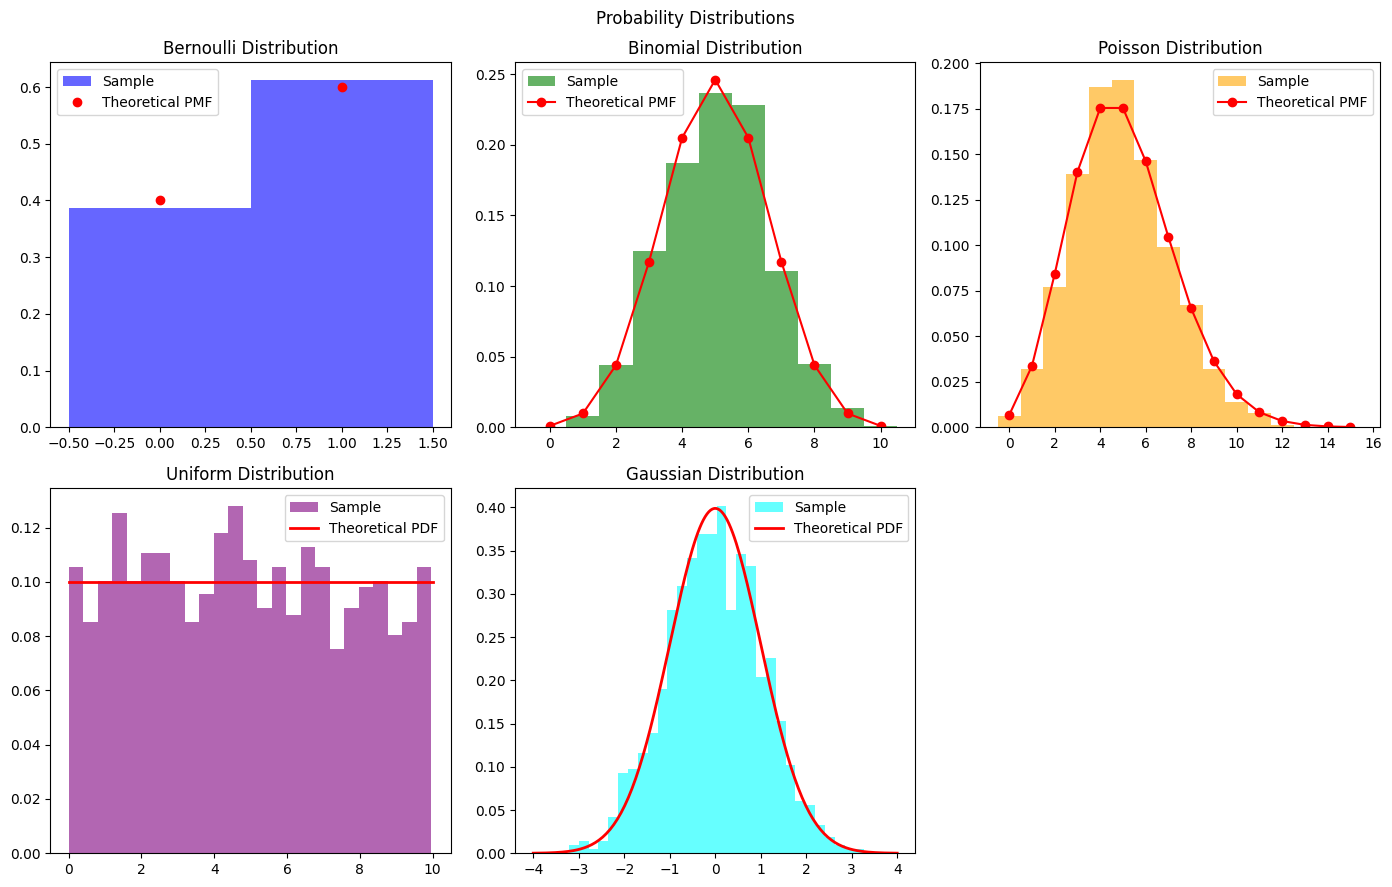

BAYES THEOREM RESULT
--------------------
Probability of Disease given Positive: 0.08755760368663597
Posterior Percentage: 8.755760368663596 %

SIMULATION RESULT
-----------------
Total Patients: 100000
Positive Test Results: 10860
True Positive Results: 929
Empirical Probability: 0.08554327808471456
Empirical Percentage: 8.554327808471456 %


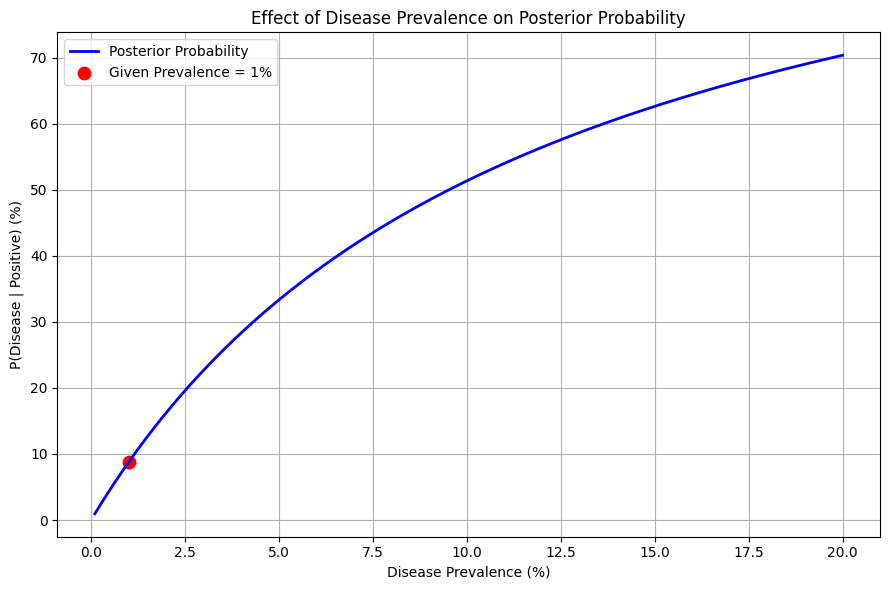

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import (
    bernoulli,
    binom,
    poisson,
    uniform,
    norm
)

np.random.seed(42)

# =====================================
# TASK 1: PROBABILITY DISTRIBUTIONS
# =====================================

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

# 1. Bernoulli Distribution
p = 0.6
samples = bernoulli.rvs(p, size=1000)

x = np.array([0, 1])

axes[0, 0].hist(
    samples,
    bins=[-0.5, 0.5, 1.5],
    density=True,
    alpha=0.6,
    color='blue',
    label='Sample'
)

axes[0, 0].plot(
    x,
    bernoulli.pmf(x, p),
    'ro',
    label='Theoretical PMF'
)

axes[0, 0].set_title('Bernoulli Distribution')
axes[0, 0].legend()

# 2. Binomial Distribution
n, p = 10, 0.5
samples = binom.rvs(n, p, size=1000)

x = np.arange(0, n + 1)

axes[0, 1].hist(
    samples,
    bins=np.arange(-0.5, n + 1.5),
    density=True,
    alpha=0.6,
    color='green',
    label='Sample'
)

axes[0, 1].plot(
    x,
    binom.pmf(x, n, p),
    'ro-',
    label='Theoretical PMF'
)

axes[0, 1].set_title('Binomial Distribution')
axes[0, 1].legend()

# 3. Poisson Distribution
lam = 5
samples = poisson.rvs(lam, size=1000)

x = np.arange(0, 16)

axes[0, 2].hist(
    samples,
    bins=np.arange(-0.5, 16.5),
    density=True,
    alpha=0.6,
    color='orange',
    label='Sample'
)

axes[0, 2].plot(
    x,
    poisson.pmf(x, lam),
    'ro-',
    label='Theoretical PMF'
)

axes[0, 2].set_title('Poisson Distribution')
axes[0, 2].legend()

# 4. Uniform Distribution
samples = uniform.rvs(
    loc=0,
    scale=10,
    size=1000
)

x = np.linspace(0, 10, 200)

axes[1, 0].hist(
    samples,
    bins=25,
    density=True,
    alpha=0.6,
    color='purple',
    label='Sample'
)

axes[1, 0].plot(
    x,
    uniform.pdf(x, loc=0, scale=10),
    'r-',
    linewidth=2,
    label='Theoretical PDF'
)

axes[1, 0].set_title('Uniform Distribution')
axes[1, 0].legend()

# 5. Gaussian (Normal) Distribution
mu, sigma = 0, 1

samples = norm.rvs(
    loc=mu,
    scale=sigma,
    size=1000
)

x = np.linspace(-4, 4, 200)

axes[1, 1].hist(
    samples,
    bins=30,
    density=True,
    alpha=0.6,
    color='cyan',
    label='Sample'
)

axes[1, 1].plot(
    x,
    norm.pdf(x, mu, sigma),
    'r-',
    linewidth=2,
    label='Theoretical PDF'
)

axes[1, 1].set_title('Gaussian Distribution')
axes[1, 1].legend()

axes[1, 2].axis('off')

plt.suptitle('Probability Distributions')
plt.tight_layout()
plt.show()


# =====================================
# TASK 2: BAYES' THEOREM
# =====================================

prevalence = 0.01
sensitivity = 0.95
specificity = 0.90

# Probability of positive test
p_positive = (
    sensitivity * prevalence
    + (1 - specificity) * (1 - prevalence)
)

# Bayes theorem
posterior = (
    sensitivity * prevalence
) / p_positive

print("BAYES THEOREM RESULT")
print("--------------------")

print(
    "Probability of Disease given Positive:",
    posterior
)

print(
    "Posterior Percentage:",
    posterior * 100, "%"
)


# =====================================
# TASK 3: SIMULATION OF 100,000 PATIENTS
# =====================================

N = 100000

# Generate disease status
disease = np.random.binomial(
    1,
    prevalence,
    N
)

# Generate test results
test_positive = np.zeros(N, dtype=int)

for i in range(N):

    if disease[i] == 1:
        test_positive[i] = np.random.binomial(
            1,
            sensitivity
        )

    else:
        test_positive[i] = np.random.binomial(
            1,
            1 - specificity
        )

# Count positive test results
positive_patients = np.sum(test_positive == 1)

# True positive patients
true_positive = np.sum(
    (disease == 1) & (test_positive == 1)
)

# Empirical probability
empirical_probability = (
    true_positive / positive_patients
)

print("\nSIMULATION RESULT")
print("-----------------")

print("Total Patients:", N)
print("Positive Test Results:", positive_patients)
print("True Positive Results:", true_positive)

print(
    "Empirical Probability:",
    empirical_probability
)

print(
    "Empirical Percentage:",
    empirical_probability * 100, "%"
)


# =====================================
# TASK 4: PREVALENCE VS POSTERIOR
# =====================================

prevalences = np.linspace(
    0.001,
    0.20,
    200
)

posterior_values = (
    sensitivity * prevalences
) / (
    sensitivity * prevalences
    + (1 - specificity) * (1 - prevalences)
)

plt.figure(figsize=(9, 6))

plt.plot(
    prevalences * 100,
    posterior_values * 100,
    color='blue',
    linewidth=2,
    label='Posterior Probability'
)

plt.scatter(
    [1],
    [posterior * 100],
    color='red',
    s=80,
    label='Given Prevalence = 1%'
)

plt.xlabel('Disease Prevalence (%)')
plt.ylabel('P(Disease | Positive) (%)')

plt.title(
    'Effect of Disease Prevalence on Posterior Probability'
)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


True Distribution: [0.5 0.3 0.2]
Model A: [0.45 0.35 0.2 ]
Model B: [0.7 0.2 0.1]

Entropy of True Distribution:
H(P) = 1.4854752972273346 bits

MODEL A RESULTS
Cross Entropy: 1.494759117548925
KL Divergence: 0.009283820321590608

MODEL B RESULTS
Cross Entropy: 1.6182506338585605
KL Divergence: 0.13277533663122576

VERIFICATION
Model A:
H(P) + KL(P||Q1) = 1.4947591175489252
Cross Entropy = 1.494759117548925

Model B:
H(P) + KL(P||Q2) = 1.6182506338585605
Cross Entropy = 1.6182506338585605

KL DIVERGENCE ASYMMETRY
KL(P||Q1) = 0.009283820321590608
KL(Q1||P) = 0.009435955417484265


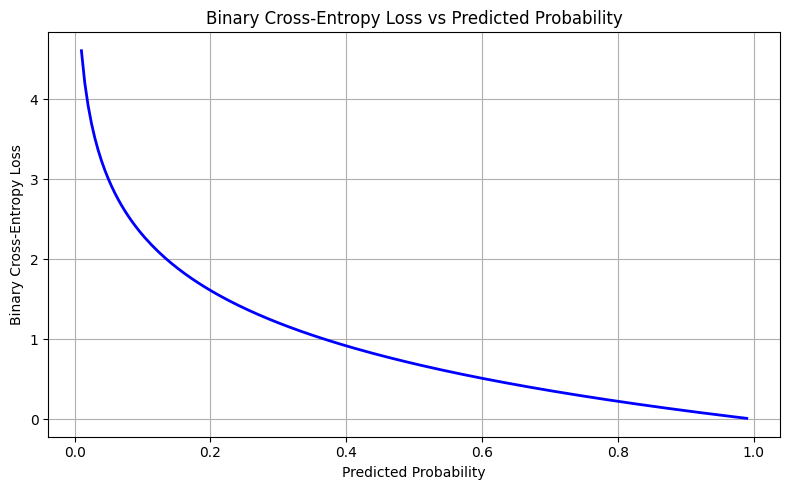

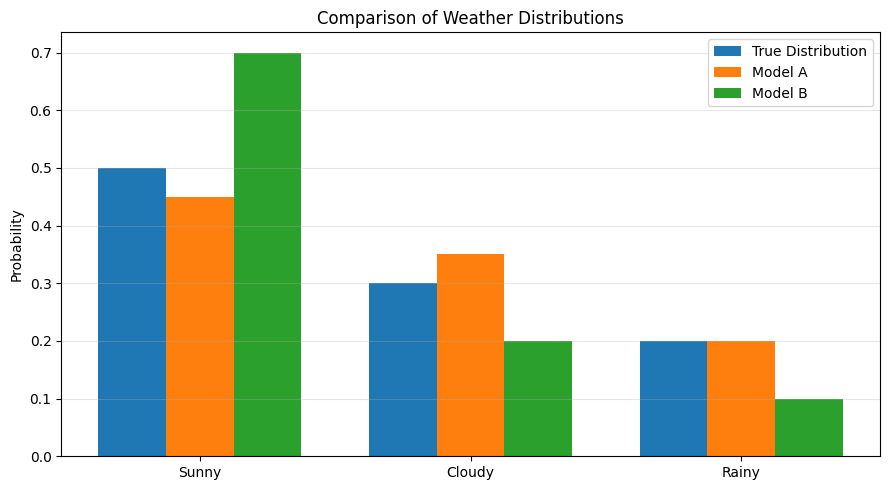

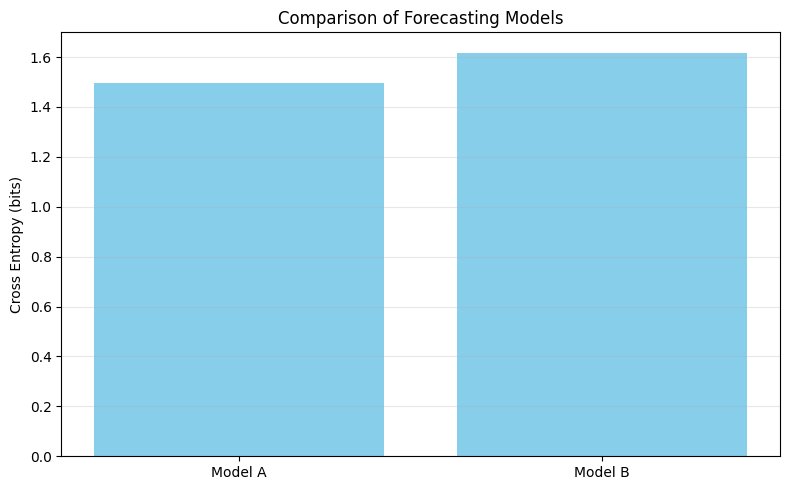


BEST FORECASTING MODEL:
Model A performs better.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import entropy

# =====================================
# 1. OBSERVED WEATHER DISTRIBUTION
# =====================================

weather = ['Sunny', 'Cloudy', 'Rainy']

# Observed weather over 30 days
true_counts = np.array([15, 9, 6])

# Convert counts into probabilities
P = true_counts / np.sum(true_counts)

# Two forecasting models
Q1 = np.array([0.45, 0.35, 0.20])
Q2 = np.array([0.70, 0.20, 0.10])

print("True Distribution:", P)
print("Model A:", Q1)
print("Model B:", Q2)


# =====================================
# 2. ENTROPY
# =====================================

H_P = entropy(P, base=2)

print("\nEntropy of True Distribution:")
print("H(P) =", H_P, "bits")


# =====================================
# 3. CROSS-ENTROPY AND KL DIVERGENCE
# =====================================

def calculate_metrics(P, Q):

    # Cross entropy
    cross_entropy = -np.sum(
        P * np.log2(Q)
    )

    # KL divergence
    kl_divergence = entropy(
        P,
        Q,
        base=2
    )

    return cross_entropy, kl_divergence


# Model A
CE1, KL1 = calculate_metrics(P, Q1)

# Model B
CE2, KL2 = calculate_metrics(P, Q2)

print("\nMODEL A RESULTS")
print("Cross Entropy:", CE1)
print("KL Divergence:", KL1)

print("\nMODEL B RESULTS")
print("Cross Entropy:", CE2)
print("KL Divergence:", KL2)


# =====================================
# 4. VERIFY THE RELATIONSHIP
# =====================================

print("\nVERIFICATION")

print("Model A:")
print("H(P) + KL(P||Q1) =", H_P + KL1)
print("Cross Entropy =", CE1)

print("\nModel B:")
print("H(P) + KL(P||Q2) =", H_P + KL2)
print("Cross Entropy =", CE2)


# =====================================
# 5. KL DIVERGENCE ASYMMETRY
# =====================================

KL_PQ = entropy(P, Q1, base=2)
KL_QP = entropy(Q1, P, base=2)

print("\nKL DIVERGENCE ASYMMETRY")
print("KL(P||Q1) =", KL_PQ)
print("KL(Q1||P) =", KL_QP)


# =====================================
# 6. BINARY CROSS-ENTROPY LOSS
# =====================================

y_true = 1

predicted_prob = np.linspace(
    0.01, 0.99, 200
)

binary_loss = -(
    y_true * np.log(predicted_prob)
    + (1 - y_true) *
    np.log(1 - predicted_prob)
)

plt.figure(figsize=(8, 5))

plt.plot(
    predicted_prob,
    binary_loss,
    color='blue',
    linewidth=2
)

plt.xlabel("Predicted Probability")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title(
    "Binary Cross-Entropy Loss vs Predicted Probability"
)

plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================
# 7. VISUAL COMPARISON OF MODELS
# =====================================

x = np.arange(len(weather))
width = 0.25

plt.figure(figsize=(9, 5))

plt.bar(
    x - width,
    P,
    width,
    label='True Distribution'
)

plt.bar(
    x,
    Q1,
    width,
    label='Model A'
)

plt.bar(
    x + width,
    Q2,
    width,
    label='Model B'
)

plt.xticks(x, weather)

plt.ylabel("Probability")
plt.title("Comparison of Weather Distributions")

plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


# =====================================
# 8. MODEL PERFORMANCE COMPARISON
# =====================================

models = ['Model A', 'Model B']
cross_entropies = [CE1, CE2]
kl_values = [KL1, KL2]

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    cross_entropies,
    color='skyblue',
    label='Cross Entropy'
)

plt.ylabel("Cross Entropy (bits)")
plt.title("Comparison of Forecasting Models")

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBEST FORECASTING MODEL:")

if CE1 < CE2:
    print("Model A performs better.")
else:
    print("Model B performs better.")


Dataset generated successfully
Number of samples: 150


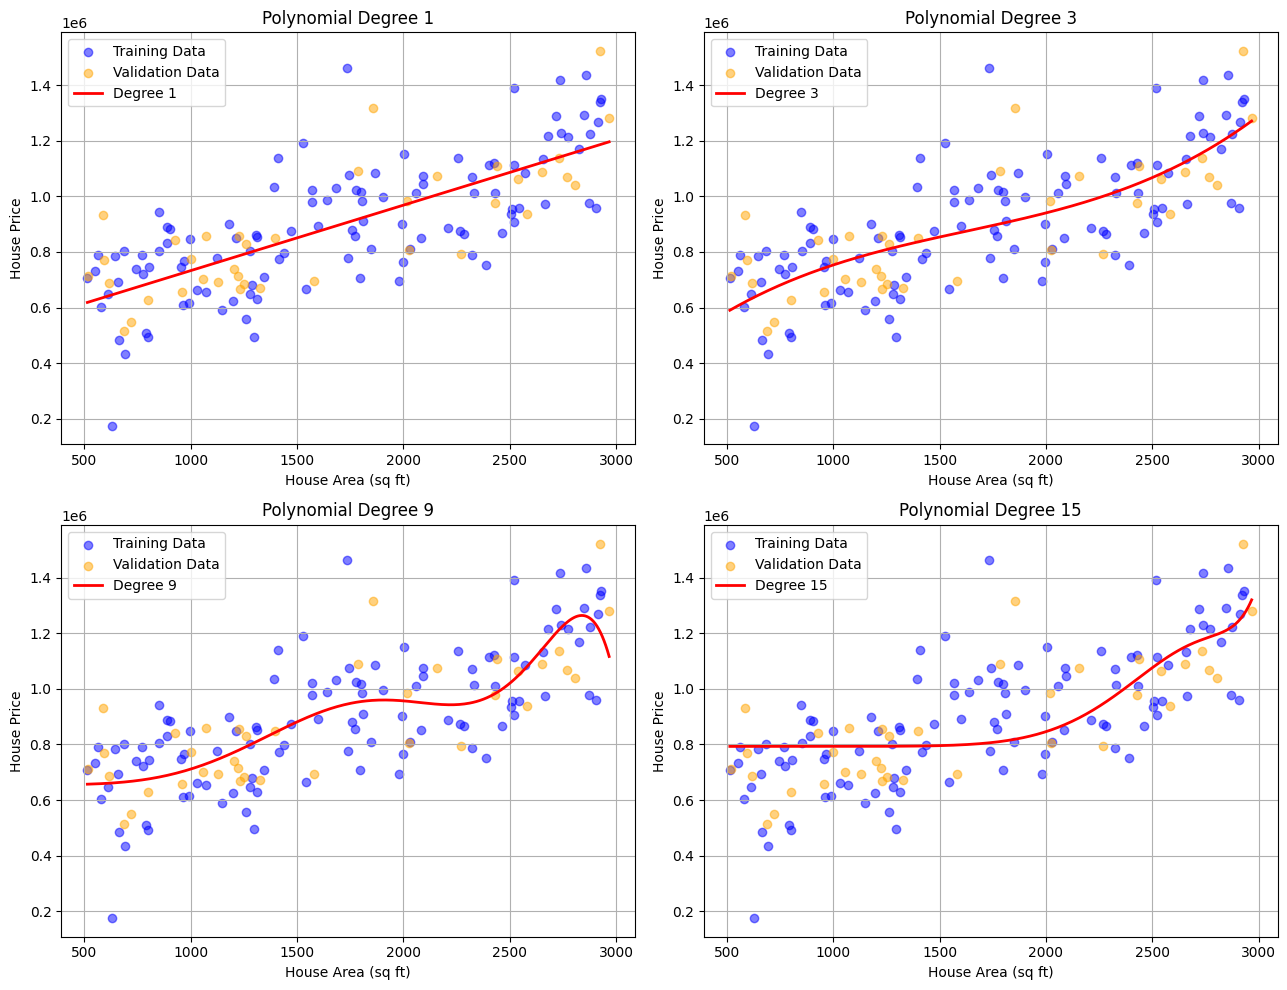

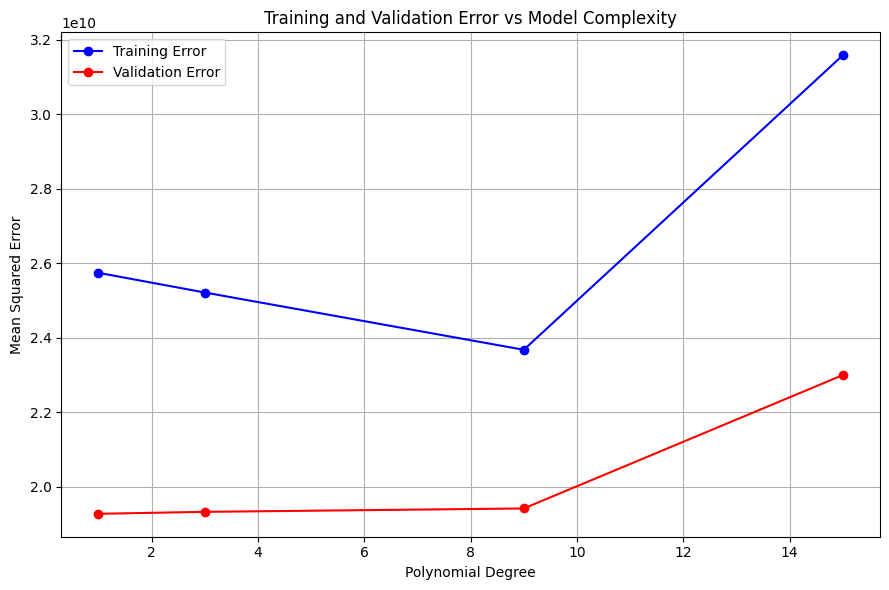


Degree 1
Bias^2: 179362721.47020903
Variance: 264353179.3924751

Degree 3
Bias^2: 14911954.168687139
Variance: 718272199.938078

Degree 9
Bias^2: 361698111.9968022
Variance: 885148030.5005641

Degree 15
Bias^2: 4484024401.812832
Variance: 852000720.8570294


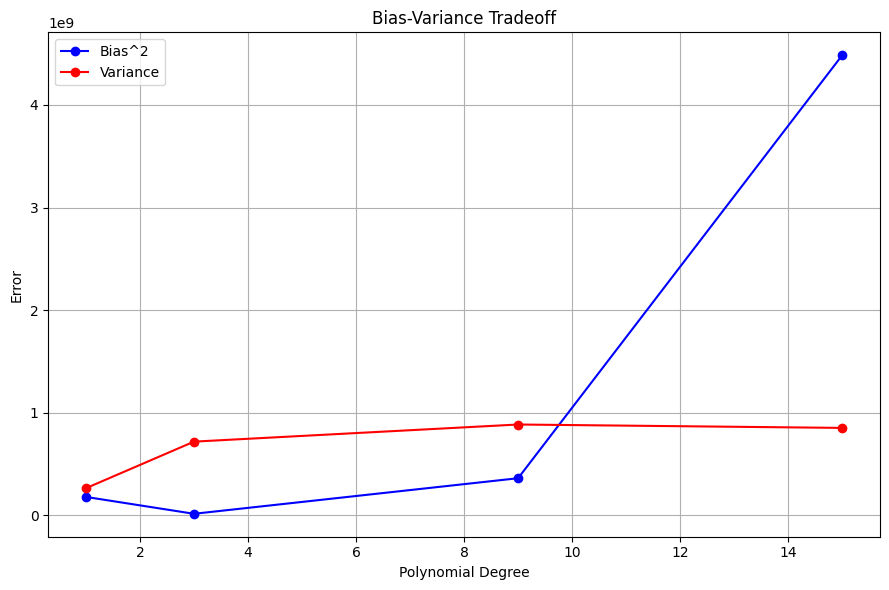


MODEL COMPARISON
----------------
Degree 1: Training MSE = 25741777328.68, Validation MSE = 19276476366.24
Degree 3: Training MSE = 25214048610.06, Validation MSE = 19328819671.31
Degree 9: Training MSE = 23677017179.44, Validation MSE = 19419484407.19
Degree 15: Training MSE = 31580009125.62, Validation MSE = 22998110010.64

Best Polynomial Degree: 1
Selected based on minimum validation MSE.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# =====================================
# 1. GENERATE HOUSE PRICE DATA
# =====================================

np.random.seed(42)

n = 150

# House area in square feet
X = np.random.uniform(500, 3000, n)

# Hidden non-linear relationship
y = (
    500000
    + 300 * X
    - 0.08 * X**2
    + 0.00002 * X**3
    + np.random.normal(0, 150000, n)
)

X = X.reshape(-1, 1)

print("Dataset generated successfully")
print("Number of samples:", n)


# =====================================
# 2. SPLIT TRAINING AND VALIDATION DATA
# =====================================

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

degrees = [1, 3, 9, 15]

train_errors = []
val_errors = []
models = []

# Smooth plotting points
X_plot = np.linspace(
    X.min(), X.max(), 300
).reshape(-1, 1)


# =====================================
# 3. POLYNOMIAL REGRESSION
# =====================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for i, degree in enumerate(degrees):

    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    # Predictions
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Calculate errors
    train_mse = mean_squared_error(
        y_train, train_pred
    )

    val_mse = mean_squared_error(
        y_val, val_pred
    )

    train_errors.append(train_mse)
    val_errors.append(val_mse)

    models.append(model)

    # Plot fitted curve
    row = i // 2
    col = i % 2

    axes[row, col].scatter(
        X_train,
        y_train,
        color='blue',
        alpha=0.5,
        label='Training Data'
    )

    axes[row, col].scatter(
        X_val,
        y_val,
        color='orange',
        alpha=0.5,
        label='Validation Data'
    )

    axes[row, col].plot(
        X_plot,
        model.predict(X_plot),
        color='red',
        linewidth=2,
        label=f'Degree {degree}'
    )

    axes[row, col].set_title(
        f'Polynomial Degree {degree}'
    )

    axes[row, col].set_xlabel(
        'House Area (sq ft)'
    )

    axes[row, col].set_ylabel(
        'House Price'
    )

    axes[row, col].legend()
    axes[row, col].grid(True)

plt.tight_layout()
plt.show()


# =====================================
# 4. TRAINING VS VALIDATION ERROR
# =====================================

plt.figure(figsize=(9, 6))

plt.plot(
    degrees,
    train_errors,
    'bo-',
    label='Training Error'
)

plt.plot(
    degrees,
    val_errors,
    'ro-',
    label='Validation Error'
)

plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error')

plt.title(
    'Training and Validation Error vs Model Complexity'
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================
# 5. BIAS^2 AND VARIANCE ESTIMATION
# =====================================

# True underlying function without noise
def true_function(x):
    return (
        500000
        + 300 * x
        - 0.08 * x**2
        + 0.00002 * x**3
    )

# Fixed test points
X_test = np.linspace(
    500, 3000, 100
).reshape(-1, 1)

y_true = true_function(
    X_test.ravel()
)

degrees = [1, 3, 9, 15]

n_simulations = 100

bias_squared = []
variances = []

rng = np.random.default_rng(42)

for degree in degrees:

    predictions = []

    for _ in range(n_simulations):

        # Generate new noisy training dataset
        X_sample = rng.uniform(
            500, 3000, 150
        )

        y_sample = (
            true_function(X_sample)
            + rng.normal(0, 150000, 150)
        )

        X_sample = X_sample.reshape(-1, 1)

        # Fit polynomial model
        model = make_pipeline(
            PolynomialFeatures(degree),
            LinearRegression()
        )

        model.fit(X_sample, y_sample)

        # Predict on fixed test points
        pred = model.predict(X_test)

        predictions.append(pred)

    predictions = np.array(predictions)

    # Average prediction
    mean_prediction = np.mean(
        predictions, axis=0
    )

    # Bias squared
    bias_sq = np.mean(
        (mean_prediction - y_true)**2
    )

    # Variance
    variance = np.mean(
        np.var(predictions, axis=0)
    )

    bias_squared.append(bias_sq)
    variances.append(variance)

    print(f"\nDegree {degree}")
    print("Bias^2:", bias_sq)
    print("Variance:", variance)


# =====================================
# 6. PLOT BIAS AND VARIANCE
# =====================================

plt.figure(figsize=(9, 6))

plt.plot(
    degrees,
    bias_squared,
    'bo-',
    label='Bias^2'
)

plt.plot(
    degrees,
    variances,
    'ro-',
    label='Variance'
)

plt.xlabel('Polynomial Degree')
plt.ylabel('Error')

plt.title(
    'Bias-Variance Tradeoff'
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# =====================================
# 7. SELECT BEST POLYNOMIAL DEGREE
# =====================================

best_index = np.argmin(val_errors)

best_degree = [1, 3, 9, 15][best_index]

print("\nMODEL COMPARISON")
print("----------------")

for degree, train_error, val_error in zip(
    [1, 3, 9, 15],
    train_errors,
    val_errors
):
    print(
        f"Degree {degree}: "
        f"Training MSE = {train_error:.2f}, "
        f"Validation MSE = {val_error:.2f}"
    )

print("\nBest Polynomial Degree:", best_degree)
print("Selected based on minimum validation MSE.")


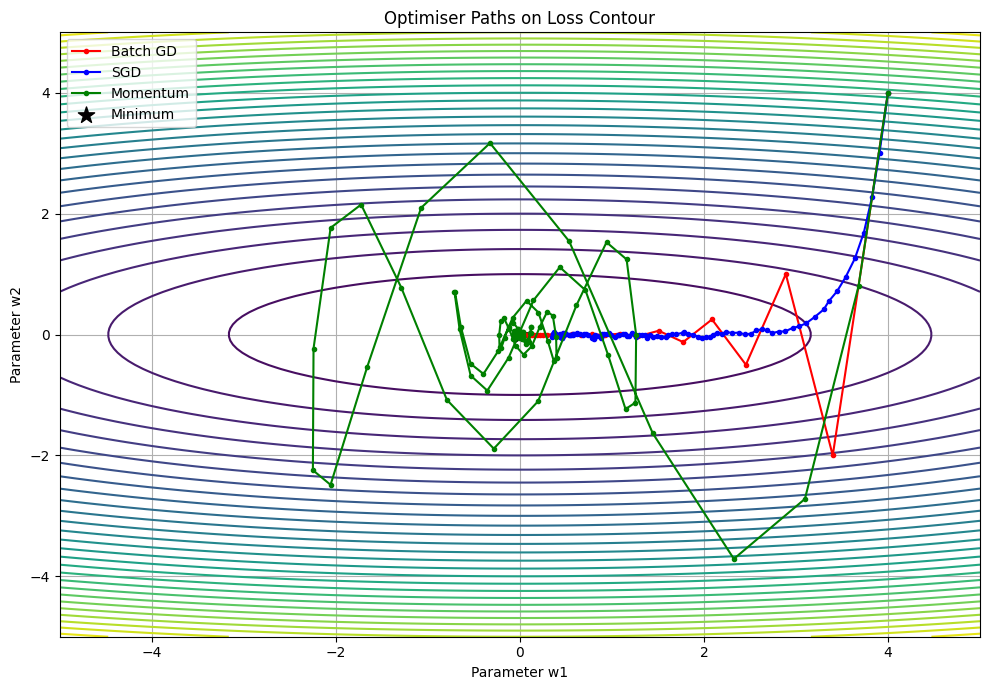


Training: SGD
Final Training Loss: 0.014850104227662086
Final Validation Loss: 0.025536151602864265

Training: SGD + Momentum
Final Training Loss: 0.01124489214271307
Final Validation Loss: 0.022006427869200706

Training: Adam
Final Training Loss: 0.012740975245833397
Final Validation Loss: 0.028385043144226074


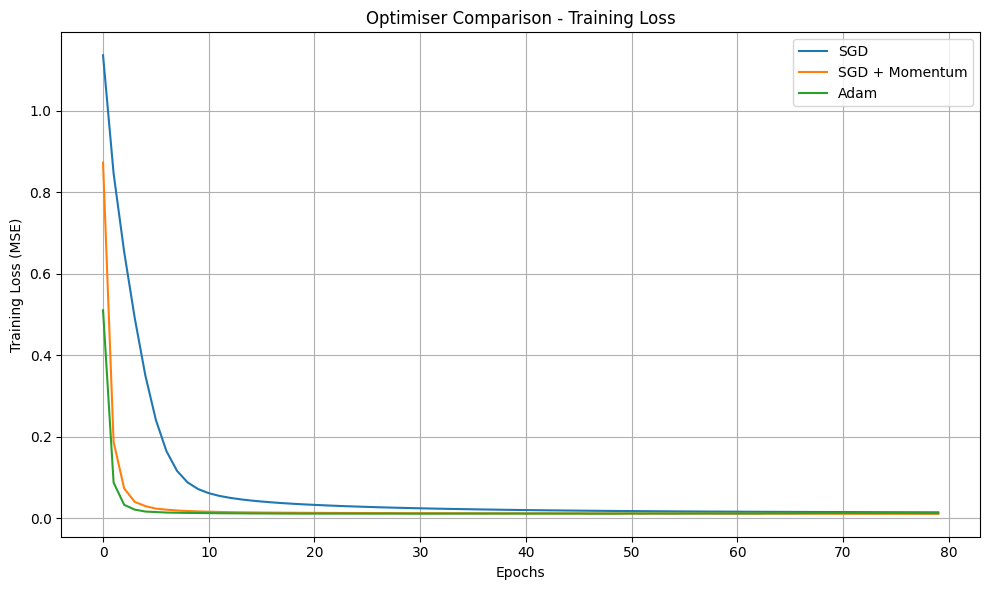

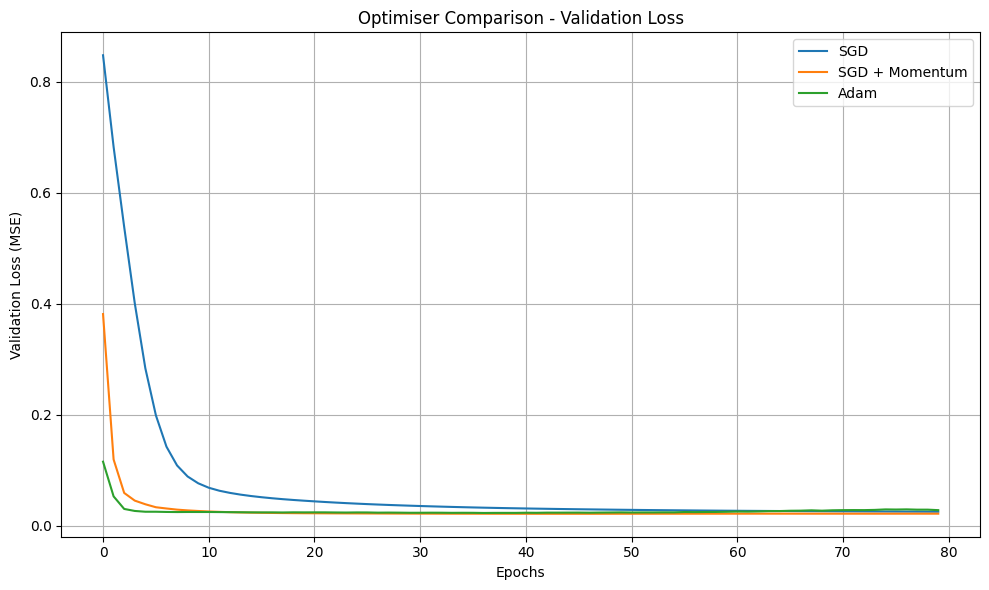


Learning Rate: 0.0001
Final Loss: 1.1459441184997559

Learning Rate: 0.01
Final Loss: 0.0207268837839365

Learning Rate: 1.0
Final Loss: 8.750349998474121


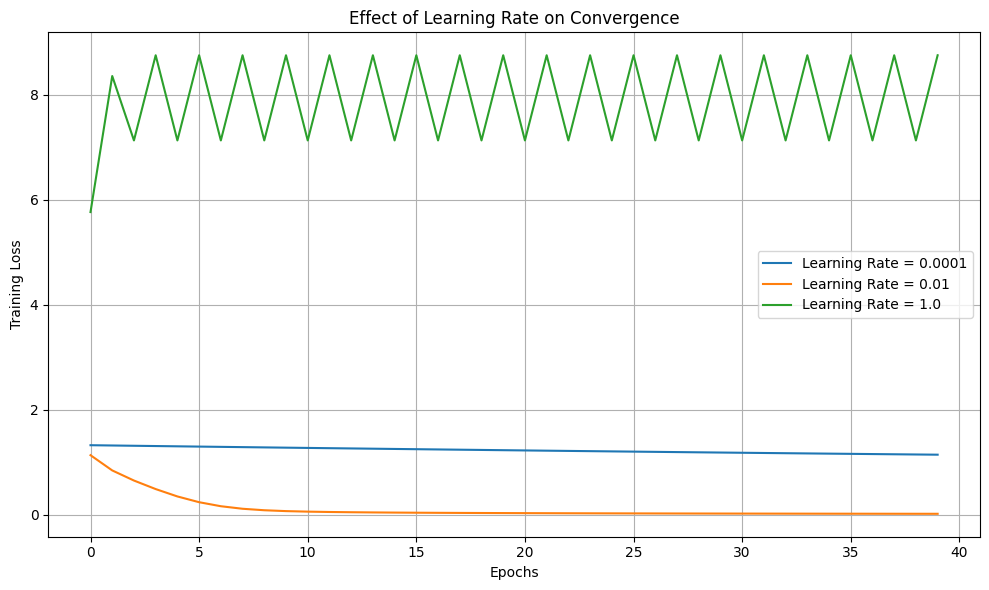


OPTIMISER PERFORMANCE SUMMARY
--------------------------------
SGD | Final Training Loss: 0.01485 | Final Validation Loss: 0.02554
SGD + Momentum | Final Training Loss: 0.01124 | Final Validation Loss: 0.02201
Adam | Final Training Loss: 0.01274 | Final Validation Loss: 0.02839

Experiment completed successfully.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# TASK 1: GENERATE DELIVERY DATASET
# ==========================================

n = 500

distance = np.random.uniform(1, 50, n)
traffic = np.random.uniform(1, 10, n)
weight = np.random.uniform(0.5, 30, n)
time_of_day = np.random.uniform(0, 24, n)

# Delivery time in minutes
delivery_time = (
    10
    + 2.5 * distance
    + 3.0 * traffic
    + 0.8 * weight
    + 0.5 * time_of_day
    + np.random.normal(0, 5, n)
)

X = np.column_stack((
    distance,
    traffic,
    weight,
    time_of_day
))

y = delivery_time.reshape(-1, 1)

# Split dataset
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Standardise input and target
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train)
X_val = x_scaler.transform(X_val)

y_train = y_scaler.fit_transform(y_train)
y_val = y_scaler.transform(y_val)


# ==========================================
# TASK 2: OPTIMISERS FROM SCRATCH
# ==========================================

# Simple two-dimensional quadratic loss
def loss_function(w):
    return 0.5 * (w[0]**2 + 10 * w[1]**2)

def gradient(w):
    return np.array([
        w[0],
        10 * w[1]
    ])

initial_point = np.array([4.0, 4.0])
iterations = 100

# Batch Gradient Descent
def batch_gd():
    w = initial_point.copy()
    path = [w.copy()]

    lr = 0.15

    for _ in range(iterations):
        grad = gradient(w)
        w = w - lr * grad
        path.append(w.copy())

    return np.array(path)


# Stochastic Gradient Descent
def sgd():
    w = initial_point.copy()
    path = [w.copy()]

    lr = 0.025

    for _ in range(iterations):
        # Simulate a noisy individual-sample gradient
        grad = gradient(w) + np.random.normal(
            0, [0.5, 1.0]
        )

        w = w - lr * grad
        path.append(w.copy())

    return np.array(path)


# SGD with Momentum
def momentum():
    w = initial_point.copy()
    velocity = np.zeros(2)

    path = [w.copy()]

    lr = 0.08
    beta = 0.9

    for _ in range(iterations):
        grad = gradient(w)

        velocity = beta * velocity + grad

        w = w - lr * velocity

        path.append(w.copy())

    return np.array(path)


# Run optimisers
path_batch = batch_gd()
path_sgd = sgd()
path_momentum = momentum()


# ==========================================
# TASK 3: PLOT 2-D LOSS CONTOUR
# ==========================================

x = np.linspace(-5, 5, 150)
y_axis = np.linspace(-5, 5, 150)

X_grid, Y_grid = np.meshgrid(x, y_axis)

Z = 0.5 * (X_grid**2 + 10 * Y_grid**2)

plt.figure(figsize=(10, 7))

plt.contour(
    X_grid,
    Y_grid,
    Z,
    levels=30,
    cmap='viridis'
)

plt.plot(
    path_batch[:, 0],
    path_batch[:, 1],
    'r.-',
    label='Batch GD'
)

plt.plot(
    path_sgd[:, 0],
    path_sgd[:, 1],
    'b.-',
    label='SGD'
)

plt.plot(
    path_momentum[:, 0],
    path_momentum[:, 1],
    'g.-',
    label='Momentum'
)

plt.scatter(
    0, 0,
    color='black',
    marker='*',
    s=150,
    label='Minimum'
)

plt.xlabel('Parameter w1')
plt.ylabel('Parameter w2')

plt.title('Optimiser Paths on Loss Contour')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# TASK 4: BUILD KERAS REGRESSION MODEL
# ==========================================

def create_model():

    model = keras.Sequential([
        keras.layers.Input(shape=(4,)),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dense(16, activation='relu'),
        keras.layers.Dense(1)
    ])

    return model


# Same initial weights for fair comparison
initial_model = create_model()
initial_weights = initial_model.get_weights()

optimizers = {
    'SGD': keras.optimizers.SGD(
        learning_rate=0.01
    ),

    'SGD + Momentum': keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    'Adam': keras.optimizers.Adam(
        learning_rate=0.01
    )
}

histories = {}

for name, optimizer in optimizers.items():

    model = create_model()

    # Use identical initial weights
    model.set_weights(initial_weights)

    model.compile(
        optimizer=optimizer,
        loss='mse',
        metrics=['mae']
    )

    print("\nTraining:", name)

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=80,
        batch_size=32,
        verbose=0
    )

    histories[name] = history.history

    print(
        "Final Training Loss:",
        history.history['loss'][-1]
    )

    print(
        "Final Validation Loss:",
        history.history['val_loss'][-1]
    )


# ==========================================
# TASK 5: PLOT LOSS AGAINST EPOCHS
# ==========================================

plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history['loss'],
        label=name
    )

plt.xlabel('Epochs')
plt.ylabel('Training Loss (MSE)')

plt.title('Optimiser Comparison - Training Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot validation losses
plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history['val_loss'],
        label=name
    )

plt.xlabel('Epochs')
plt.ylabel('Validation Loss (MSE)')

plt.title('Optimiser Comparison - Validation Loss')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# TASK 6: VARY LEARNING RATE
# ==========================================

learning_rates = [0.0001, 0.01, 1.0]

lr_histories = {}

for lr in learning_rates:

    model = create_model()
    model.set_weights(initial_weights)

    model.compile(
        optimizer=keras.optimizers.SGD(
            learning_rate=lr
        ),
        loss='mse'
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=40,
        batch_size=32,
        verbose=0
    )

    lr_histories[lr] = history.history['loss']

    print(
        f"\nLearning Rate: {lr}"
    )

    print(
        "Final Loss:",
        history.history['loss'][-1]
    )


# Plot learning rate comparison
plt.figure(figsize=(10, 6))

for lr, losses in lr_histories.items():

    plt.plot(
        losses,
        label=f'Learning Rate = {lr}'
    )

plt.xlabel('Epochs')
plt.ylabel('Training Loss')

plt.title('Effect of Learning Rate on Convergence')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# TASK 7: FINAL COMPARISON
# ==========================================

print("\nOPTIMISER PERFORMANCE SUMMARY")
print("--------------------------------")

for name, history in histories.items():

    print(
        name,
        "| Final Training Loss:",
        round(history['loss'][-1], 5),
        "| Final Validation Loss:",
        round(history['val_loss'][-1], 5)
    )

print("\nExperiment completed successfully.")


Loan Dataset
Total Applications: 100
Approved: 46
Rejected: 54
Epoch 1: Weights=[0.17933332 0.19825824], Bias=-0.2000, Errors=24
Epoch 2: Weights=[0.27136052 0.25851829], Bias=-0.3000, Errors=15
Epoch 3: Weights=[0.33086505 0.2868128 ], Bias=-0.3000, Errors=8
Epoch 4: Weights=[0.40626551 0.26302031], Bias=-0.4000, Errors=13
Epoch 5: Weights=[0.4631058  0.33643485], Bias=-0.4000, Errors=10
Epoch 6: Weights=[0.45677111 0.37247817], Bias=-0.4000, Errors=2
Epoch 7: Weights=[0.5260088  0.39964501], Bias=-0.4000, Errors=8
Epoch 8: Weights=[0.52805529 0.36029972], Bias=-0.5000, Errors=9
Epoch 9: Weights=[0.63052711 0.33663086], Bias=-0.5000, Errors=12
Epoch 10: Weights=[0.59632427 0.50014242], Bias=-0.5000, Errors=8
Epoch 11: Weights=[0.62818223 0.40614607], Bias=-0.6000, Errors=9
Epoch 12: Weights=[0.64387474 0.43622655], Bias=-0.6000, Errors=6
Epoch 13: Weights=[0.68800632 0.40531225], Bias=-0.6000, Errors=6
Epoch 14: Weights=[0.73270938 0.40086892], Bias=-0.6000, Errors=8
Epoch 15: Weights

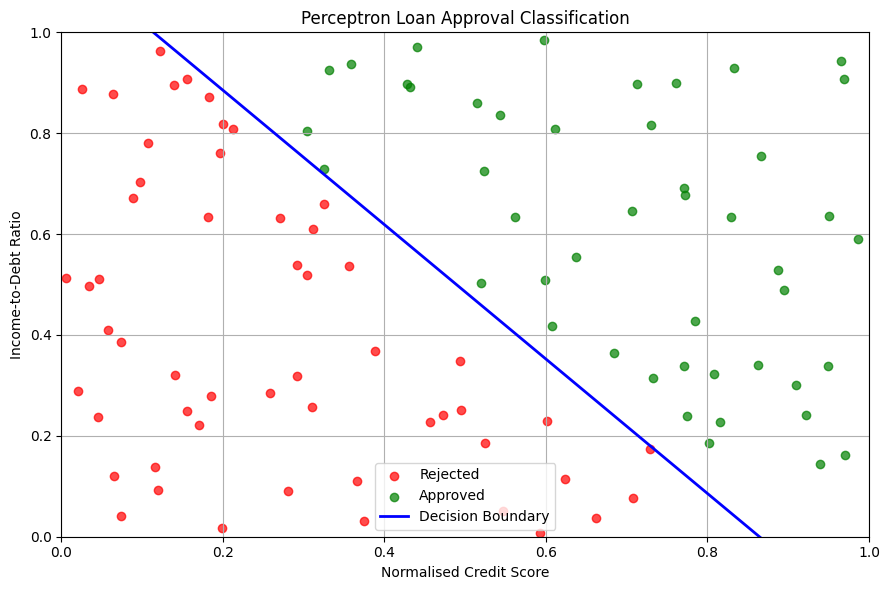

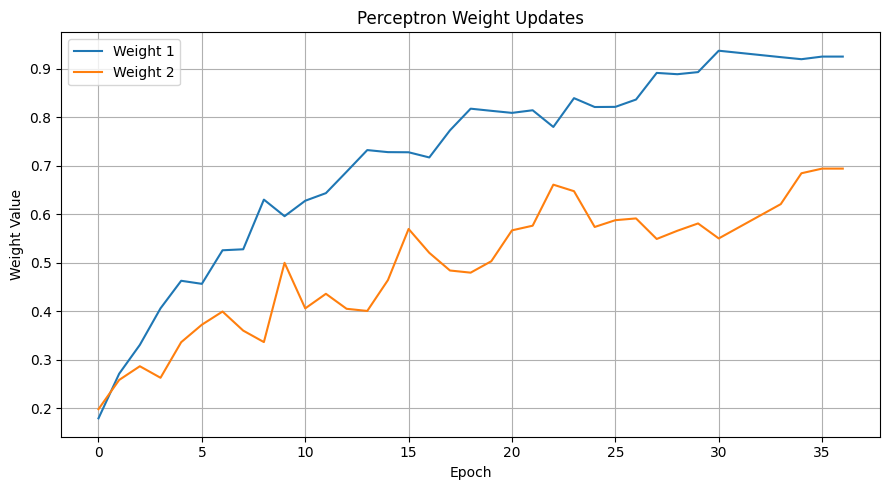

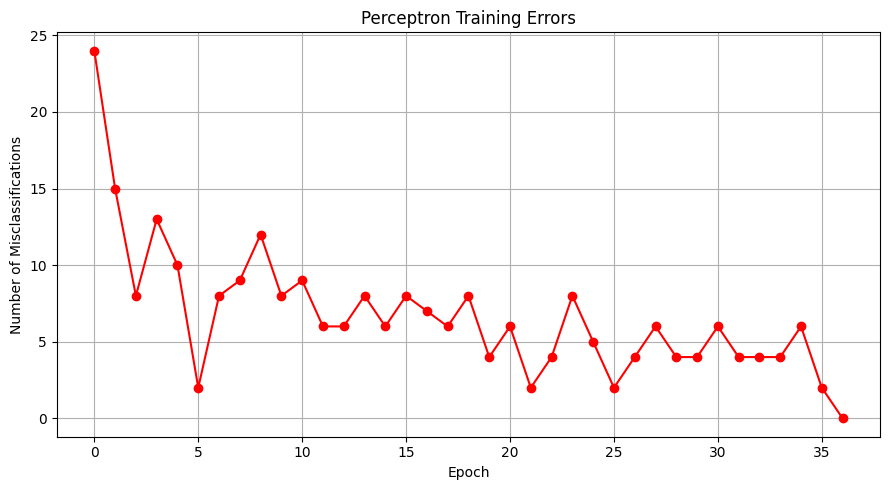

XOR Epoch 1: Weights=[-0.1  0. ], Bias=-0.100, Errors=3
XOR Epoch 2: Weights=[-0.1  0. ], Bias=0.000, Errors=3
XOR Epoch 3: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 4: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 5: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 6: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 7: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 8: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 9: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 10: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 11: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 12: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 13: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 14: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 15: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 16: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 17: Weights=[-0.1  0. ], Bias=0.000, Errors=4
XOR Epoch 18: Weights=[-0.1  0. ], Bias=0.000, Errors=4


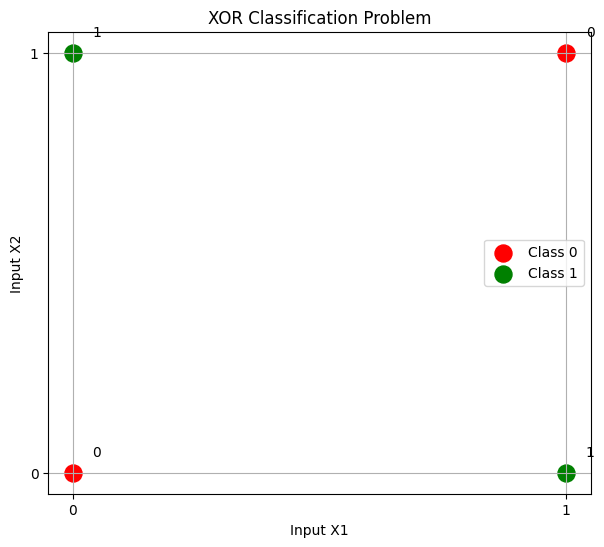


ACTIVATION FUNCTION COMPARISON
Input: [-2 -1  0  1  2]
Step: [0 0 1 1 1]
Sigmoid: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]
ReLU: [0 0 0 1 2]


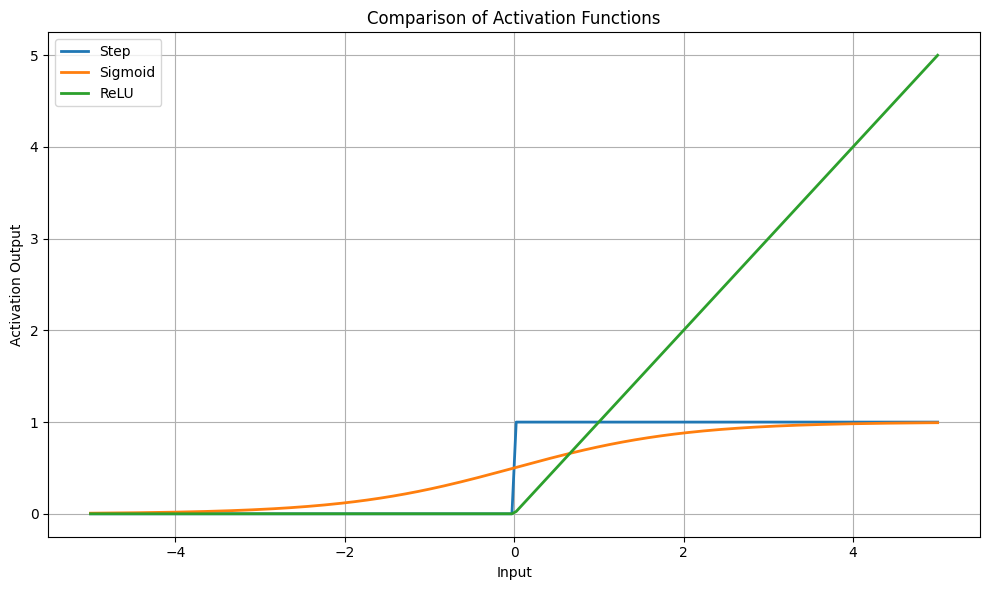


Experiment completed successfully.


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ==========================================
# TASK 1: ACTIVATION FUNCTIONS
# ==========================================

def step(z):
    return np.where(z >= 0, 1, 0)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)


# Forward propagation
def forward_propagation(X, weights, bias):
    z = np.dot(X, weights) + bias
    output = step(z)
    return z, output


# ==========================================
# TASK 2: GENERATE LOAN DATASET
# ==========================================

n = 100

# Credit score: 300 to 850
credit_score = np.random.uniform(300, 850, n)

# Income-to-debt ratio: 0 to 1
income_debt = np.random.uniform(0, 1, n)

# Normalise credit score
credit_normalized = (
    credit_score - 300
) / 550

X = np.column_stack((
    credit_normalized,
    income_debt
))

# Generate linearly separable labels
y = (
    credit_normalized
    + 0.8 * income_debt > 0.9
).astype(int)

print("Loan Dataset")
print("Total Applications:", n)
print("Approved:", np.sum(y == 1))
print("Rejected:", np.sum(y == 0))


# ==========================================
# TASK 3: PERCEPTRON TRAINING
# ==========================================

weights = np.zeros(2)
bias = 0.0

learning_rate = 0.1
epochs = 50

weight_history = []
bias_history = []
errors_history = []

for epoch in range(epochs):

    errors = 0

    for i in range(n):

        # Forward propagation
        z, prediction = forward_propagation(
            X[i],
            weights,
            bias
        )

        # Calculate error
        error = y[i] - prediction

        # Perceptron learning rule
        weights = (
            weights
            + learning_rate * error * X[i]
        )

        bias = (
            bias
            + learning_rate * error
        )

        if error != 0:
            errors += 1

    # Record updates after each epoch
    weight_history.append(weights.copy())
    bias_history.append(bias)
    errors_history.append(errors)

    print(
        f"Epoch {epoch+1}: "
        f"Weights={weights}, "
        f"Bias={bias:.4f}, "
        f"Errors={errors}"
    )

    if errors == 0:
        print("Perceptron converged!")
        break


# ==========================================
# TASK 4: PLOT DECISION BOUNDARY
# ==========================================

plt.figure(figsize=(9, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    color='red',
    label='Rejected',
    alpha=0.7
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    color='green',
    label='Approved',
    alpha=0.7
)

# Decision boundary:
# w1*x1 + w2*x2 + bias = 0

x_values = np.linspace(0, 1, 100)

if abs(weights[1]) > 1e-10:

    y_values = (
        -weights[0] * x_values - bias
    ) / weights[1]

    plt.plot(
        x_values,
        y_values,
        color='blue',
        linewidth=2,
        label='Decision Boundary'
    )

plt.xlabel('Normalised Credit Score')
plt.ylabel('Income-to-Debt Ratio')

plt.title('Perceptron Loan Approval Classification')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# TASK 5: WEIGHT UPDATES PER EPOCH
# ==========================================

weight_history = np.array(weight_history)

plt.figure(figsize=(9, 5))

plt.plot(
    weight_history[:, 0],
    label='Weight 1'
)

plt.plot(
    weight_history[:, 1],
    label='Weight 2'
)

plt.xlabel('Epoch')
plt.ylabel('Weight Value')

plt.title('Perceptron Weight Updates')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot errors per epoch
plt.figure(figsize=(9, 5))

plt.plot(
    errors_history,
    marker='o',
    color='red'
)

plt.xlabel('Epoch')
plt.ylabel('Number of Misclassifications')

plt.title('Perceptron Training Errors')

plt.grid(True)
plt.tight_layout()
plt.show()


# ==========================================
# TASK 6: XOR DATASET
# ==========================================

X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y_xor = np.array([0, 1, 1, 0])

xor_weights = np.zeros(2)
xor_bias = 0.0

xor_errors_history = []

for epoch in range(20):

    errors = 0

    for i in range(4):

        z, prediction = forward_propagation(
            X_xor[i],
            xor_weights,
            xor_bias
        )

        error = y_xor[i] - prediction

        xor_weights += (
            learning_rate * error * X_xor[i]
        )

        xor_bias += learning_rate * error

        if error != 0:
            errors += 1

    xor_errors_history.append(errors)

    print(
        f"XOR Epoch {epoch+1}: "
        f"Weights={xor_weights}, "
        f"Bias={xor_bias:.3f}, "
        f"Errors={errors}"
    )

print("\nXOR Final Predictions:")

for i in range(4):

    _, prediction = forward_propagation(
        X_xor[i],
        xor_weights,
        xor_bias
    )

    print(
        X_xor[i],
        "Actual:", y_xor[i],
        "Predicted:", prediction
    )


# ==========================================
# TASK 7: XOR VISUALISATION
# ==========================================

plt.figure(figsize=(7, 6))

plt.scatter(
    X_xor[y_xor == 0, 0],
    X_xor[y_xor == 0, 1],
    color='red',
    s=150,
    label='Class 0'
)

plt.scatter(
    X_xor[y_xor == 1, 0],
    X_xor[y_xor == 1, 1],
    color='green',
    s=150,
    label='Class 1'
)

for i, point in enumerate(X_xor):
    plt.text(
        point[0] + 0.04,
        point[1] + 0.04,
        str(y_xor[i])
    )

plt.xlabel('Input X1')
plt.ylabel('Input X2')

plt.title('XOR Classification Problem')

plt.xticks([0, 1])
plt.yticks([0, 1])

plt.legend()
plt.grid(True)
plt.show()


# ==========================================
# TASK 8: COMPARE ACTIVATION FUNCTIONS
# ==========================================

inputs = np.array([
    -2, -1, 0, 1, 2
])

step_output = step(inputs)
sigmoid_output = sigmoid(inputs)
relu_output = relu(inputs)

print("\nACTIVATION FUNCTION COMPARISON")

print("Input:", inputs)
print("Step:", step_output)
print("Sigmoid:", sigmoid_output)
print("ReLU:", relu_output)


# Plot activation functions
x = np.linspace(-5, 5, 200)

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    step(x),
    label='Step',
    linewidth=2
)

plt.plot(
    x,
    sigmoid(x),
    label='Sigmoid',
    linewidth=2
)

plt.plot(
    x,
    relu(x),
    label='ReLU',
    linewidth=2
)

plt.xlabel('Input')
plt.ylabel('Activation Output')

plt.title('Comparison of Activation Functions')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


print("\nExperiment completed successfully.")



========== XOR DATASET ==========

Gradient Checking
Numerical Gradient: 0.005104739014827331
Analytical Gradient: 0.005104739014450358
Absolute Difference: 3.7697275856451995e-13
Epoch 0, Loss: 0.789806
Epoch 500, Loss: 0.102263
Epoch 1000, Loss: 0.027114
Epoch 1500, Loss: 0.014675
Epoch 2000, Loss: 0.009888
Epoch 2500, Loss: 0.007399
Epoch 3000, Loss: 0.005885
Epoch 3500, Loss: 0.004872
Epoch 4000, Loss: 0.004148
Epoch 4500, Loss: 0.003606

Actual Output:
[[0.]
 [1.]
 [1.]
 [0.]]

Predicted Output:
[[0]
 [1]
 [1]
 [0]]

XOR Accuracy: 100.0 %


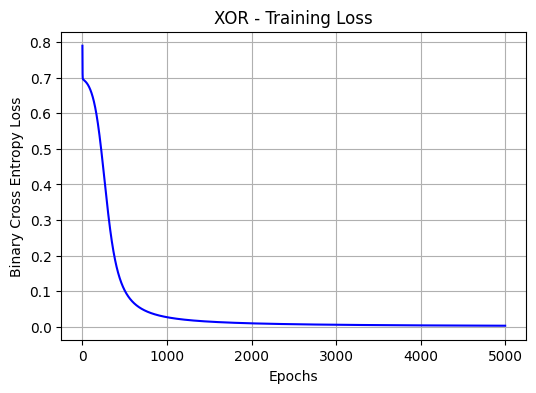

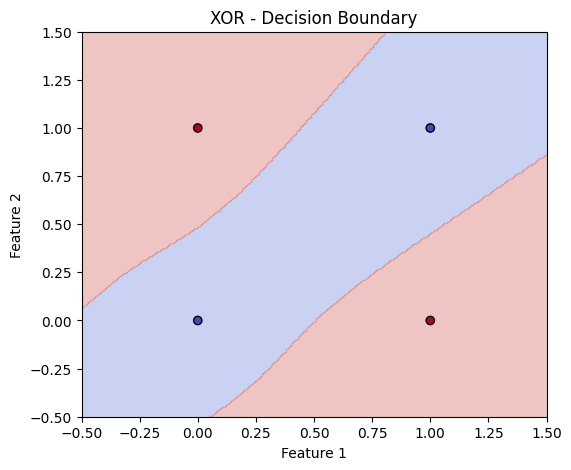


========== TWO MOONS DATASET ==========
Epoch 0, Loss: 0.752594
Epoch 500, Loss: 0.264456
Epoch 1000, Loss: 0.262796
Epoch 1500, Loss: 0.258923
Epoch 2000, Loss: 0.223417
Epoch 2500, Loss: 0.150486
Epoch 3000, Loss: 0.105541
Epoch 3500, Loss: 0.079259
Epoch 4000, Loss: 0.062934
Epoch 4500, Loss: 0.051955

Two Moons Accuracy: 99.33333333333333 %


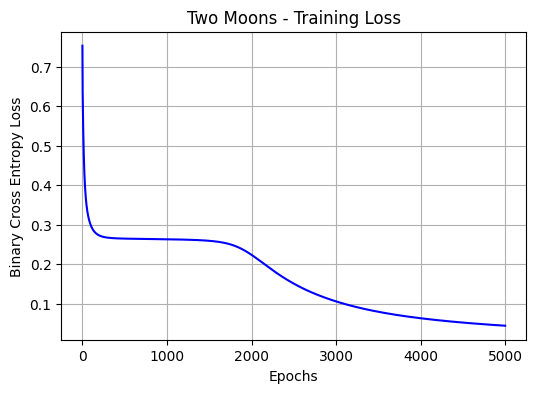

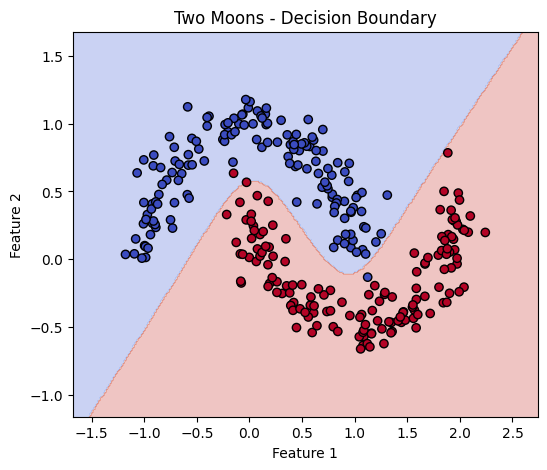

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Create XOR Dataset
# -----------------------------------------

def create_xor():
    X = np.array([
        [0, 0],
        [0, 1],
        [1, 0],
        [1, 1]
    ], dtype=float)

    Y = np.array([
        [0],
        [1],
        [1],
        [0]
    ], dtype=float)

    return X, Y


# -----------------------------------------
# 2. Create Two Moons Dataset
# -----------------------------------------

def create_moons(n=300, noise=0.12):
    np.random.seed(42)

    n1 = n // 2
    n2 = n - n1

    theta1 = np.random.rand(n1) * np.pi
    theta2 = np.random.rand(n2) * np.pi

    moon1 = np.column_stack((
        np.cos(theta1),
        np.sin(theta1)
    ))

    moon2 = np.column_stack((
        1 - np.cos(theta2),
        0.5 - np.sin(theta2)
    ))

    X = np.vstack((moon1, moon2))
    X += noise * np.random.randn(n, 2)

    Y = np.vstack((
        np.zeros((n1, 1)),
        np.ones((n2, 1))
    ))

    return X, Y


# -----------------------------------------
# 3. Sigmoid Activation Function
# -----------------------------------------

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# -----------------------------------------
# 4. Initialize Network Parameters
# -----------------------------------------

def initialize_parameters(input_size, hidden_size, output_size):

    np.random.seed(42)

    W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
    b1 = np.zeros((1, hidden_size))

    W2 = np.random.randn(hidden_size, output_size) * np.sqrt(2 / hidden_size)
    b2 = np.zeros((1, output_size))

    return W1, b1, W2, b2


# -----------------------------------------
# 5. Forward Propagation
# -----------------------------------------

def forward_propagation(X, W1, b1, W2, b2):

    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2


# -----------------------------------------
# 6. Calculate Binary Cross Entropy Loss
# -----------------------------------------

def calculate_loss(Y, A2):

    m = Y.shape[0]

    A2 = np.clip(A2, 1e-12, 1 - 1e-12)

    loss = -np.sum(
        Y * np.log(A2) +
        (1 - Y) * np.log(1 - A2)
    ) / m

    return loss


# -----------------------------------------
# 7. Backpropagation
# -----------------------------------------

def backward_propagation(X, Y, A1, A2, W2):

    m = X.shape[0]

    # Output layer gradient
    dZ2 = A2 - Y

    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer gradient
    dZ1 = np.dot(dZ2, W2.T) * A1 * (1 - A1)

    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2


# -----------------------------------------
# 8. Train Neural Network
# -----------------------------------------

def train_network(X, Y, hidden_size=8,
                  learning_rate=0.5, epochs=5000):

    input_size = X.shape[1]
    output_size = 1

    W1, b1, W2, b2 = initialize_parameters(
        input_size, hidden_size, output_size
    )

    losses = []

    for epoch in range(epochs):

        # Forward propagation
        Z1, A1, Z2, A2 = forward_propagation(
            X, W1, b1, W2, b2
        )

        # Calculate loss
        loss = calculate_loss(Y, A2)
        losses.append(loss)

        # Backward propagation
        dW1, db1, dW2, db2 = backward_propagation(
            X, Y, A1, A2, W2
        )

        # Gradient descent
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1

        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss: {loss:.6f}")

    return W1, b1, W2, b2, losses


# -----------------------------------------
# 9. Prediction
# -----------------------------------------

def predict(X, W1, b1, W2, b2):

    _, _, _, A2 = forward_propagation(
        X, W1, b1, W2, b2
    )

    return (A2 >= 0.5).astype(int)


# -----------------------------------------
# 10. Numerical Gradient Checking
# -----------------------------------------

def gradient_check(X, Y):

    W1, b1, W2, b2 = initialize_parameters(2, 4, 1)

    _, A1, _, A2 = forward_propagation(
        X, W1, b1, W2, b2
    )

    dW1, db1, dW2, db2 = backward_propagation(
        X, Y, A1, A2, W2
    )

    epsilon = 1e-5

    # Check one weight in W1
    W1_plus = W1.copy()
    W1_minus = W1.copy()

    W1_plus[0, 0] += epsilon
    W1_minus[0, 0] -= epsilon

    _, _, _, A_plus = forward_propagation(
        X, W1_plus, b1, W2, b2
    )

    _, _, _, A_minus = forward_propagation(
        X, W1_minus, b1, W2, b2
    )

    loss_plus = calculate_loss(Y, A_plus)
    loss_minus = calculate_loss(Y, A_minus)

    numerical_gradient = (
        loss_plus - loss_minus
    ) / (2 * epsilon)

    analytical_gradient = dW1[0, 0]

    print("\nGradient Checking")
    print("Numerical Gradient:", numerical_gradient)
    print("Analytical Gradient:", analytical_gradient)

    difference = abs(
        numerical_gradient - analytical_gradient
    )

    print("Absolute Difference:", difference)

    return difference


# -----------------------------------------
# 11. Plot Loss and Decision Boundary
# -----------------------------------------

def plot_results(X, Y, losses, parameters, title):

    W1, b1, W2, b2 = parameters

    # Plot loss
    plt.figure(figsize=(6, 4))

    plt.plot(losses, color="blue")
    plt.xlabel("Epochs")
    plt.ylabel("Binary Cross Entropy Loss")
    plt.title(title + " - Training Loss")
    plt.grid(True)
    plt.show()

    # Create mesh grid
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    Z = predict(grid, W1, b1, W2, b2)
    Z = Z.reshape(xx.shape)

    # Plot decision boundary
    plt.figure(figsize=(6, 5))

    plt.contourf(
        xx, yy, Z,
        alpha=0.3,
        cmap=plt.cm.coolwarm
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=Y.ravel(),
        cmap=plt.cm.coolwarm,
        edgecolors="black"
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(title + " - Decision Boundary")
    plt.show()


# =========================================
# 12. EXPERIMENT EXECUTION
# =========================================

# XOR experiment
print("\n========== XOR DATASET ==========")

X_xor, Y_xor = create_xor()

gradient_check(X_xor, Y_xor)

params_xor = train_network(
    X_xor, Y_xor,
    hidden_size=8,
    learning_rate=0.5,
    epochs=5000
)

W1, b1, W2, b2, losses_xor = params_xor

predictions = predict(X_xor, W1, b1, W2, b2)

print("\nActual Output:")
print(Y_xor)

print("\nPredicted Output:")
print(predictions)

print("\nXOR Accuracy:",
      np.mean(predictions == Y_xor) * 100, "%")

plot_results(
    X_xor, Y_xor, losses_xor,
    (W1, b1, W2, b2), "XOR"
)


# Two Moons experiment
print("\n========== TWO MOONS DATASET ==========")

X_moons, Y_moons = create_moons()

params_moons = train_network(
    X_moons, Y_moons,
    hidden_size=12,
    learning_rate=0.5,
    epochs=5000
)

W1, b1, W2, b2, losses_moons = params_moons

predictions_moons = predict(
    X_moons, W1, b1, W2, b2
)

accuracy = np.mean(
    predictions_moons == Y_moons
) * 100

print("\nTwo Moons Accuracy:", accuracy, "%")

plot_results(
    X_moons, Y_moons, losses_moons,
    (W1, b1, W2, b2), "Two Moons"
)


Dataset Sample:
   Tenure  MonthlyCharges        Contract  Complaints  DataUsage  Churn
0      52      100.153711  Month-to-month           2   8.341751      1
1      15      115.957664  Month-to-month           1  89.253933      1
2      72       68.785404  Month-to-month           3  84.920439      1
3      61       30.973620  Month-to-month           2  99.266398      0
4      21       74.795949        Two year           0  68.259955      0

Dataset Shape: (2000, 6)

Churn Distribution:
Churn
0    1151
1     849
Name: count, dtype: int64

Training Shape: (1280, 7)
Validation Shape: (320, 7)
Testing Shape: (400, 7)


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.6766 - loss: 0.6386 - val_accuracy: 0.6969 - val_loss: 0.6071
Epoch 2/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7109 - loss: 0.5689 - val_accuracy: 0.6844 - val_loss: 0.5783
Epoch 3/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7258 - loss: 0.5466 - val_accuracy: 0.6844 - val_loss: 0.5735
Epoch 4/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7297 - loss: 0.5396 - val_accuracy: 0.6844 - val_loss: 0.5741
Epoch 5/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7312 - loss: 0.5364 - val_accuracy: 0.6844 - val_loss: 0.5752
Epoch 6/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7344 - loss: 0.5337 - val_accuracy: 0.6844 - val_loss: 0.5763
Epoch 7/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7352 - loss: 0.5316 - val_accuracy: 0.6875 - val_loss: 0.5772
Epoch 8/100
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7375 - loss: 0.5295 - val_accuracy: 0.6844 

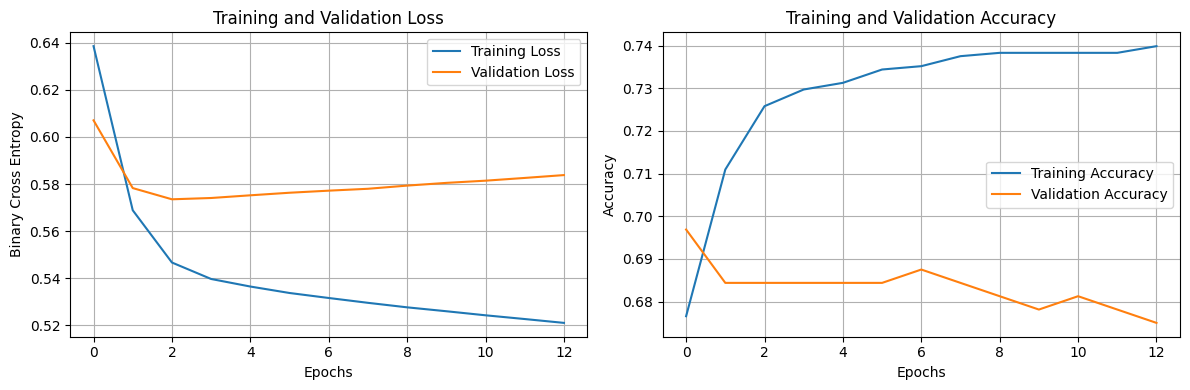


========== MODEL EVALUATION ==========
Accuracy : 0.7175
Precision: 0.6508
Recall   : 0.7235
F1 Score : 0.6852

Classification Report:
              precision    recall  f1-score   support

         0.0       0.78      0.71      0.74       230
         1.0       0.65      0.72      0.69       170

    accuracy                           0.72       400
   macro avg       0.71      0.72      0.71       400
weighted avg       0.72      0.72      0.72       400


Confusion Matrix:
[[164  66]
 [ 47 123]]


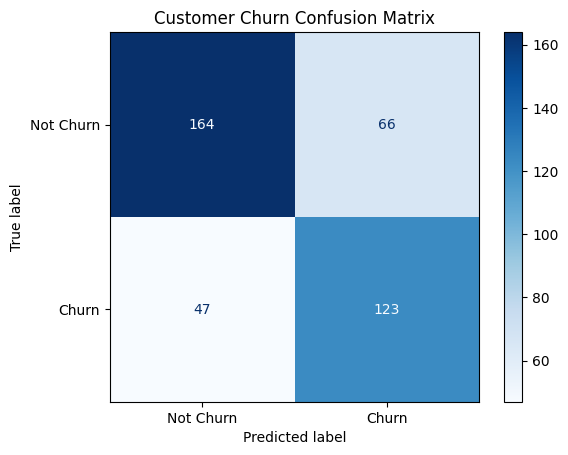


Training model with width = 16

Training model with width = 32

Training model with width = 64

Training model with width = 128

========== WIDTH COMPARISON ==========
 Hidden Width  Accuracy  Precision   Recall  F1 Score
           16     0.720   0.654255 0.723529  0.687151
           32     0.720   0.662921 0.694118  0.678161
           64     0.715   0.640000 0.752941  0.691892
          128     0.730   0.663158 0.741176  0.700000


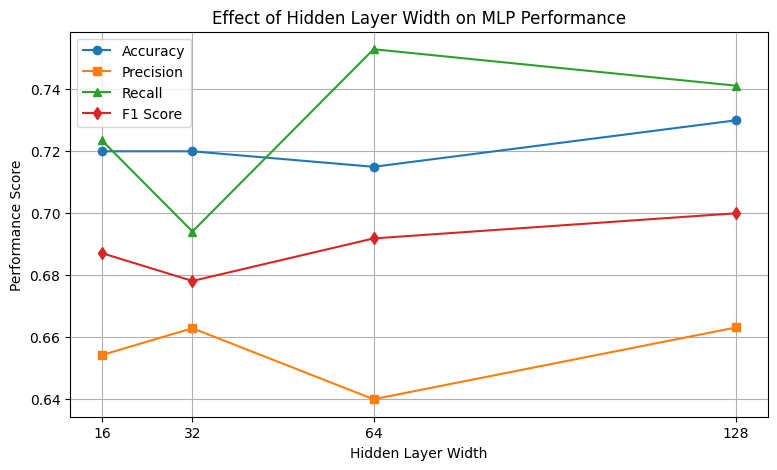

In [ ]:

# ==========================================
# EXPERIMENT 9: MULTILAYER PERCEPTRON (MLP)
# Customer Churn Prediction using Keras
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# ------------------------------------------
# 1. Generate Sample Telecom Churn Dataset
# ------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

n = 2000

df = pd.DataFrame({
    "Tenure": np.random.randint(1, 73, n),
    "MonthlyCharges": np.random.uniform(20, 120, n),
    "Contract": np.random.choice(
        ["Month-to-month", "One year", "Two year"],
        n,
        p=[0.55, 0.25, 0.20]
    ),
    "Complaints": np.random.poisson(1.5, n),
    "DataUsage": np.random.uniform(1, 100, n)
})

# Generate churn probabilities
score = (
    1.2 * (df["Contract"] == "Month-to-month").astype(int)
    - 0.035 * df["Tenure"]
    + 0.025 * (df["MonthlyCharges"] - 70)
    + 0.35 * df["Complaints"]
    - 0.008 * df["DataUsage"]
)

probability = 1 / (1 + np.exp(-score))

df["Churn"] = (
    np.random.rand(n) < probability
).astype(int)

print("Dataset Sample:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nChurn Distribution:")
print(df["Churn"].value_counts())


# ------------------------------------------
# 2. Separate Features and Target
# ------------------------------------------

X = df.drop("Churn", axis=1)
y = df["Churn"]

numeric_features = [
    "Tenure",
    "MonthlyCharges",
    "Complaints",
    "DataUsage"
]

categorical_features = ["Contract"]


# ------------------------------------------
# 3. Split Dataset
# ------------------------------------------

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)


# ------------------------------------------
# 4. Data Preprocessing
# ------------------------------------------

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train = preprocessor.fit_transform(X_train)
X_val = preprocessor.transform(X_val)
X_test = preprocessor.transform(X_test)

# Convert to dense NumPy arrays
X_train = np.asarray(X_train, dtype=np.float32)
X_val = np.asarray(X_val, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_val = y_val.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

print("\nTraining Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)


# ------------------------------------------
# 5. Build MLP Model
# ------------------------------------------

def build_model(input_dim, width=64):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),

        tf.keras.layers.Dense(
            width, activation="relu"
        ),

        tf.keras.layers.Dense(
            width // 2, activation="relu"
        ),

        tf.keras.layers.Dense(
            width // 4, activation="relu"
        ),

        tf.keras.layers.Dense(
            1, activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------
# 6. Train MLP Model
# ------------------------------------------

model = build_model(
    input_dim=X_train.shape[1],
    width=64
)

model.summary()

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)


# ------------------------------------------
# 7. Plot Training and Validation Curves
# ------------------------------------------

plt.figure(figsize=(12, 4))

# Loss graph
plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy")
plt.legend()
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------
# 8. Model Evaluation
# ------------------------------------------

y_probability = model.predict(X_test, verbose=0)

y_pred = (y_probability >= 0.5).astype(int).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n========== MODEL EVALUATION ==========")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))


# ------------------------------------------
# 9. Confusion Matrix
# ------------------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Customer Churn Confusion Matrix")
plt.show()


# ------------------------------------------
# 10. Compare Different Hidden Layer Widths
# ------------------------------------------

widths = [16, 32, 64, 128]

results = []

for width in widths:

    print(f"\nTraining model with width = {width}")

    temp_model = build_model(
        input_dim=X_train.shape[1],
        width=width
    )

    temp_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=100,
        batch_size=32,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )

    temp_probability = temp_model.predict(
        X_test, verbose=0
    )

    temp_pred = (
        temp_probability >= 0.5
    ).astype(int).ravel()

    acc = accuracy_score(y_test, temp_pred)
    prec = precision_score(
        y_test, temp_pred, zero_division=0
    )
    rec = recall_score(
        y_test, temp_pred, zero_division=0
    )
    f1_value = f1_score(
        y_test, temp_pred, zero_division=0
    )

    results.append([
        width, acc, prec, rec, f1_value
    ])


# ------------------------------------------
# 11. Display Width Comparison
# ------------------------------------------

results_df = pd.DataFrame(
    results,
    columns=[
        "Hidden Width",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n========== WIDTH COMPARISON ==========")
print(results_df.to_string(index=False))


# ------------------------------------------
# 12. Plot Width Comparison
# ------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    results_df["Hidden Width"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["Hidden Width"],
    results_df["Precision"],
    marker="s",
    label="Precision"
)

plt.plot(
    results_df["Hidden Width"],
    results_df["Recall"],
    marker="^",
    label="Recall"
)

plt.plot(
    results_df["Hidden Width"],
    results_df["F1 Score"],
    marker="d",
    label="F1 Score"
)

plt.xlabel("Hidden Layer Width")
plt.ylabel("Performance Score")
plt.title("Effect of Hidden Layer Width on MLP Performance")

plt.xticks(widths)
plt.legend()
plt.grid(True)
plt.show()


Dataset Sample:
   Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
0          6.0   98.830157      80.531520      30.500521   89.915076   
1          3.0   82.128819      77.331160      15.316555   70.938326   
2          4.0  108.837126      67.668406      26.053755  100.534283   
3          6.0  141.409970      85.911958      11.659745   63.378372   
4          2.0  125.352344      59.027240      18.986324  110.495405   

         BMI  DiabetesPedigreeFunction   Age  Outcome  
0  28.995289                  0.227786  66.0        0  
1  36.119873                  0.280344  64.0        0  
2  20.813130                  1.997896  24.0        0  
3  35.235209                  0.720615  49.0        1  
4  46.170167                  1.521549  43.0        1  

Dataset Shape: (500, 9)

Class Distribution:
Outcome
1    319
0    181
Name: count, dtype: int64

Training Shape: (300, 8)
Validation Shape: (100, 8)
Testing Shape: (100, 8)

========== BASELINE MODEL ==========
Ba

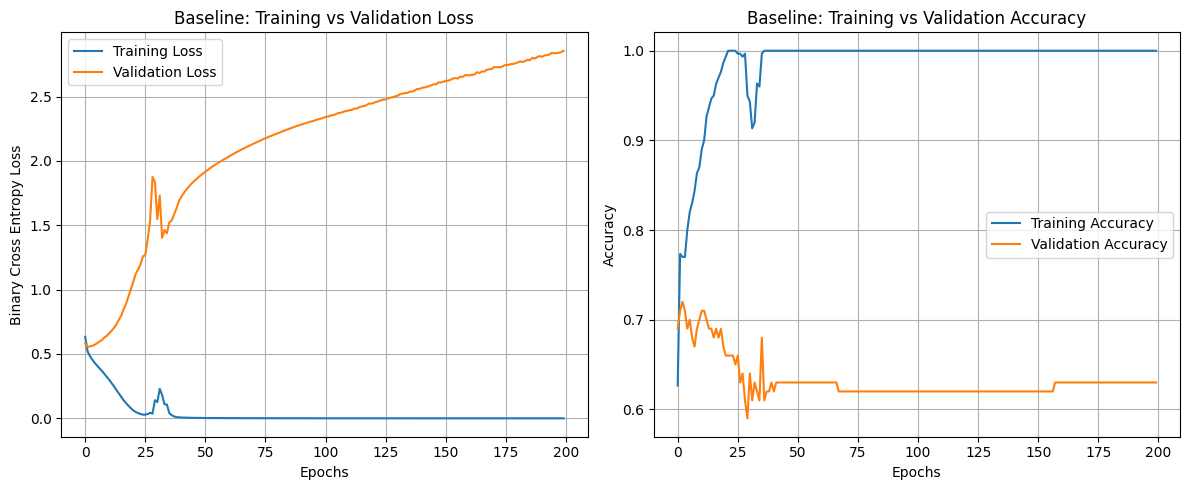

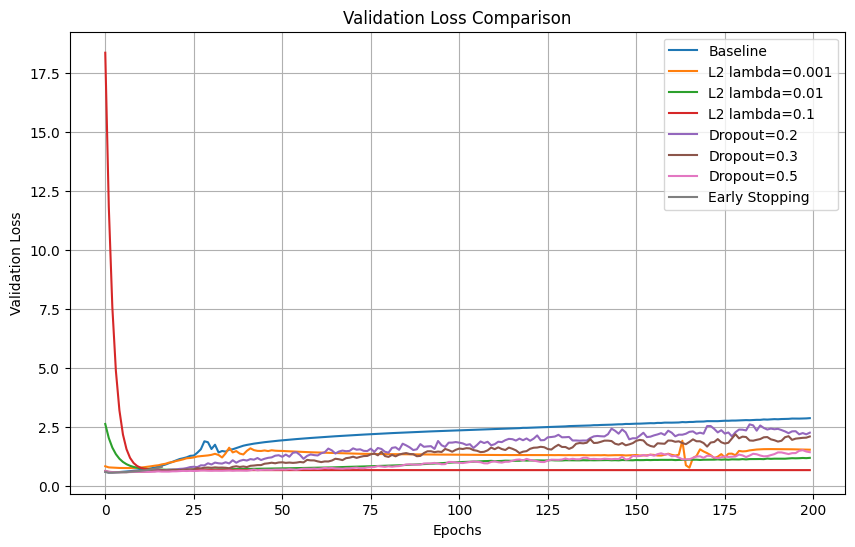

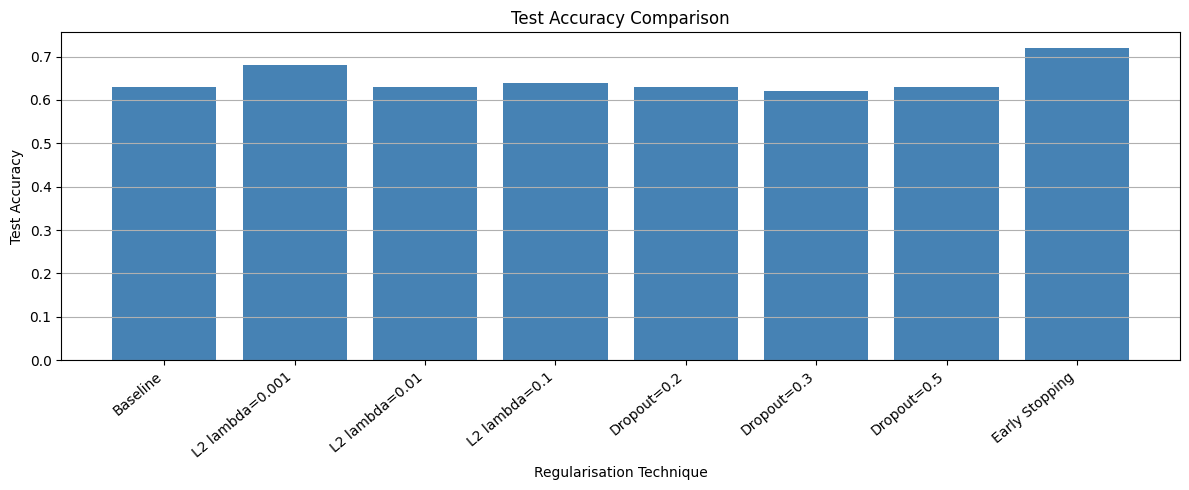

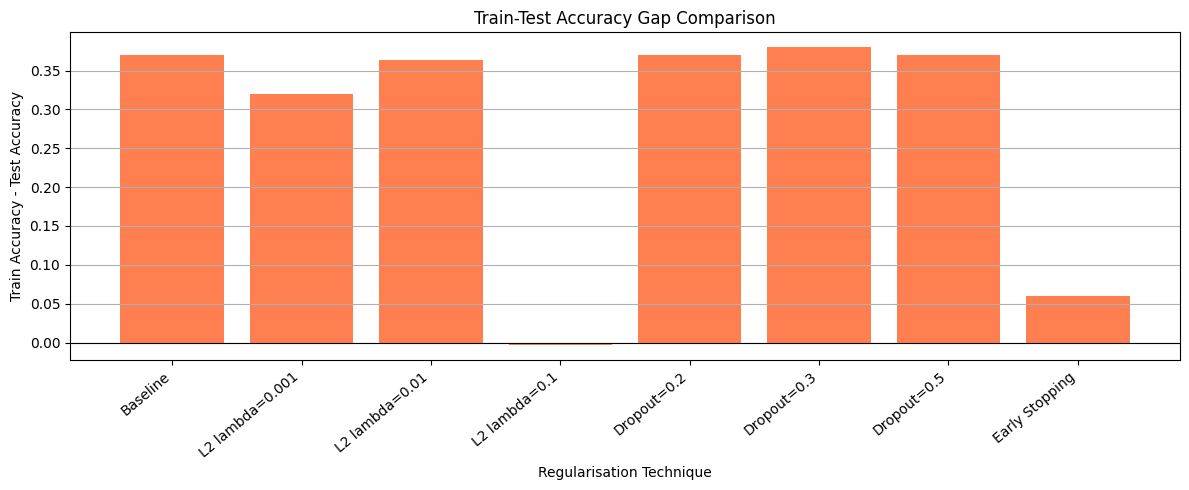

In [ ]:

# ==============================================
# EXPERIMENT 10
# L2, DROPOUT AND EARLY STOPPING COMPARISON
# Diabetes Prediction using TensorFlow and Keras
# ==============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# ----------------------------------------------
# 1. Generate Synthetic Diabetes Dataset
# ----------------------------------------------

np.random.seed(42)
tf.random.set_seed(42)

n = 500

X = np.column_stack([
    np.random.randint(0, 8, n),            # Pregnancies
    np.random.normal(120, 25, n),          # Glucose
    np.random.normal(72, 12, n),           # Blood Pressure
    np.random.normal(25, 10, n),           # Skin Thickness
    np.random.normal(80, 35, n),           # Insulin
    np.random.normal(32, 7, n),            # BMI
    np.random.uniform(0.1, 2.0, n),        # Diabetes pedigree
    np.random.randint(21, 75, n)           # Age
])

X = np.maximum(X, 0)

# Generate diabetes probability
risk = (
    0.035 * (X[:, 1] - 120)
    + 0.08 * (X[:, 5] - 32)
    + 0.025 * (X[:, 7] - 40)
    + 0.45 * (X[:, 6] - 0.8)
    + 0.12 * X[:, 0]
)

probability = 1 / (1 + np.exp(-risk))

y = (
    np.random.rand(n) < probability
).astype(int)

feature_names = [
    "Pregnancies", "Glucose", "BloodPressure",
    "SkinThickness", "Insulin", "BMI",
    "DiabetesPedigreeFunction", "Age"
]

df = pd.DataFrame(X, columns=feature_names)
df["Outcome"] = y

print("Dataset Sample:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["Outcome"].value_counts())


# ----------------------------------------------
# 2. Split Dataset
# ----------------------------------------------

X = df.drop("Outcome", axis=1).values
y = df["Outcome"].values

# 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


# ----------------------------------------------
# 3. Feature Scaling
# ----------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("\nTraining Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)


# ----------------------------------------------
# 4. Build MLP Model
# ----------------------------------------------

def build_model(l2_lambda=0, dropout_rate=0):

    regularizer = (
        tf.keras.regularizers.l2(l2_lambda)
        if l2_lambda > 0 else None
    )

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(8,)),

        tf.keras.layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            64,
            activation="relu",
            kernel_regularizer=regularizer
        ),

        tf.keras.layers.Dense(
            1,
            activation="sigmoid"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# ----------------------------------------------
# 5. Train and Evaluate Model
# ----------------------------------------------

results = []
histories = {}

def train_and_evaluate(
    name,
    l2_lambda=0,
    dropout_rate=0,
    early_stopping=False,
    epochs=200
):

    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = build_model(
        l2_lambda=l2_lambda,
        dropout_rate=dropout_rate
    )

    callbacks = []

    if early_stopping:
        callbacks.append(
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=15,
                restore_best_weights=True,
                min_delta=0.001
            )
        )

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=16,
        callbacks=callbacks,
        verbose=0
    )

    # Evaluate using inference mode
    train_probability = model.predict(
        X_train, verbose=0
    ).ravel()

    test_probability = model.predict(
        X_test, verbose=0
    ).ravel()

    train_pred = (
        train_probability >= 0.5
    ).astype(int)

    test_pred = (
        test_probability >= 0.5
    ).astype(int)

    train_accuracy = accuracy_score(
        y_train, train_pred
    )

    test_accuracy = accuracy_score(
        y_test, test_pred
    )

    gap = train_accuracy - test_accuracy

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Train-Test Gap": gap,
        "Epochs": len(history.history["loss"])
    })

    histories[name] = history.history

    print(
        f"{name}: "
        f"Train={train_accuracy:.4f}, "
        f"Test={test_accuracy:.4f}, "
        f"Gap={gap:.4f}, "
        f"Epochs={len(history.history['loss'])}"
    )

    return model


# ----------------------------------------------
# 6. Baseline Model
# ----------------------------------------------

print("\n========== BASELINE MODEL ==========")

baseline_model = train_and_evaluate(
    "Baseline",
    epochs=200
)


# ----------------------------------------------
# 7. L2 Regularisation Comparison
# ----------------------------------------------

print("\n========== L2 REGULARISATION ==========")

for lam in [0.001, 0.01, 0.1]:

    train_and_evaluate(
        f"L2 lambda={lam}",
        l2_lambda=lam,
        epochs=200
    )


# ----------------------------------------------
# 8. Dropout Comparison
# ----------------------------------------------

print("\n========== DROPOUT COMPARISON ==========")

for rate in [0.2, 0.3, 0.5]:

    train_and_evaluate(
        f"Dropout={rate}",
        dropout_rate=rate,
        epochs=200
    )


# ----------------------------------------------
# 9. Early Stopping Comparison
# ----------------------------------------------

print("\n========== EARLY STOPPING ==========")

early_model = train_and_evaluate(
    "Early Stopping",
    early_stopping=True,
    epochs=300
)


# ----------------------------------------------
# 10. Display Comparison Table
# ----------------------------------------------

results_df = pd.DataFrame(results)

print("\n========== FINAL MODEL COMPARISON ==========")

print(
    results_df.to_string(
        index=False,
        formatters={
            "Train Accuracy": "{:.4f}".format,
            "Test Accuracy": "{:.4f}".format,
            "Train-Test Gap": "{:.4f}".format
        }
    )
)


# ----------------------------------------------
# 11. Plot Baseline Overfitting
# ----------------------------------------------

baseline_history = histories["Baseline"]

plt.figure(figsize=(12, 5))

# Loss curves
plt.subplot(1, 2, 1)

plt.plot(
    baseline_history["loss"],
    label="Training Loss"
)

plt.plot(
    baseline_history["val_loss"],
    label="Validation Loss"
)

plt.title("Baseline: Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross Entropy Loss")
plt.legend()
plt.grid(True)

# Accuracy curves
plt.subplot(1, 2, 2)

plt.plot(
    baseline_history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    baseline_history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Baseline: Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


# ----------------------------------------------
# 12. Compare Validation Loss Curves
# ----------------------------------------------

plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# ----------------------------------------------
# 13. Compare Test Accuracy
# ----------------------------------------------

plt.figure(figsize=(12, 5))

plt.bar(
    results_df["Model"],
    results_df["Test Accuracy"],
    color="steelblue"
)

plt.title("Test Accuracy Comparison")
plt.xlabel("Regularisation Technique")
plt.ylabel("Test Accuracy")
plt.xticks(rotation=40, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# ----------------------------------------------
# 14. Compare Train-Test Gap
# ----------------------------------------------

plt.figure(figsize=(12, 5))

plt.bar(
    results_df["Model"],
    results_df["Train-Test Gap"],
    color="coral"
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Train-Test Accuracy Gap Comparison")
plt.xlabel("Regularisation Technique")
plt.ylabel("Train Accuracy - Test Accuracy")
plt.xticks(rotation=40, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()
